# Figures for the revised DESI+PFS manuscript

All **nine numbered figures** in `paper/PFSxDESI-multi-fish-author-revision.tex`,
from the verified forecasts using **Table 2 of Takada et al. (2014)** for PFS.
The main PFS range is $0.6\leq z\leq1.6$. Figures 1–5 and 7 use the corrected
density prescription. Figures 6, 8 and 9 retain their DESI-only or analytic inputs.
This notebook renders the saved results without recomputing spectra or Fisher forecasts.

**Run:** choose a Python kernel with NumPy and Matplotlib, then **Restart Kernel and Run All**.
The plotting code is directly in this notebook, with one data cell and one plotting
cell per figure. The small input files live in `data/author_revision/`; no numerical
worktree, cosmology emulator or one-loop package is needed.

**Hand editing:** use the shared style cell for fonts and colours; use the `FIGSIZE`,
axis limits and legend arguments in each figure cell for local changes. Re-run that
cell to refresh its PDF, PNG and SVG. `EXPORT = True` overwrites the corresponding
files used by the revised manuscript; set it to `False` for an on-screen experiment,
or change `OUTPUT_DIR` to save alternatives. Recompile the LaTeX manuscript to see
updated figures in the paper. This notebook never edits the manuscript text.

Typography follows `figures.ipynb` and its `pfsfog.plots.set_style()` call: STIX serif
text and mathematics, inward ticks on all sides, a boxed frame, and no background
grid. Labels are enlarged for the final manuscript width. Explanations belong here
and in the captions, rather than in long plot subtitles.

The comparisons retain the revised scientific definitions: growth is derived from
the global cosmology. A is the correlated-auto reference. A–B, B–C and C–D
add measured spectra with their prescribed nuisance freedom; B–D is the total PFS increment.

Subsamples are numbered by increasing nominal redshift within each population:
LRG-1–4, ELG-1–4, QSO-1–6 and PFS-ELG-1–5 in the main comparison.
These forecast labels do not in general match DESI DR1 or DR2 sample definitions
or bin boundaries. Radial subdivisions sharing a nuisance set retain one label.

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import platform
import sys
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
from matplotlib.ticker import MaxNLocator, NullFormatter

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
plt.rcParams['font.size'] = 24

# Works when launched from the repository root, notebooks/, or a subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'notebooks/data/author_revision/manifest.json').is_file())
DATA_DIR = ROOT / 'notebooks/data/author_revision'
OUTPUT_DIR = ROOT / 'paper/figs/author-revision'
EXPORT = True
FORMATS = ('pdf', 'png', 'svg')
PNG_DPI = 200

manifest = json.loads((DATA_DIR / 'manifest.json').read_text())
for name, record in manifest['files'].items():
    actual = hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
    assert actual == record['sha256'], f'Input differs from saved result: {name}'
print(f'Checked {len(manifest["files"])} input files. Output: {OUTPUT_DIR}')

Checked 11 input files. Output: /Users/nguyenmn/PFSxDESI-multi-fish/paper/figs/author-revision


## Shared plotting style and export controls

Font sizes below are for a 14-inch-wide three-panel canvas reduced to the paper's
440-TeX-point text width (about 6.1 inches). Thus 22-point labels appear at about
9.6 points in the paper. Figure 3 uses a single panel with its own canvas and font
sizes. Figure 8 also uses its own smaller canvas and font sizes because it occupies
only three quarters of the manuscript width. Each figure retains an explicit size,
so changing one plot does not silently change the others.

In [2]:
plt.rcdefaults()
plt.rcParams.update({
    'text.usetex': False,
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
    'font.size': 22,
    'axes.labelsize': 23,
    'axes.titlesize': 24,
    'xtick.labelsize': 21,
    'ytick.labelsize': 21,
    'legend.fontsize': 20,
    'figure.dpi': 120,
    'axes.linewidth': 1.2,
    'axes.unicode_minus': False,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.major.width': 1, 'ytick.major.width': 1,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'xtick.minor.width': .8, 'ytick.minor.width': .8,
    'axes.grid': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none',
    'svg.hashsalt': 'desi-pfs-revised-notebook',
    'savefig.bbox': None,
})
# Original notebook colour family; Fig. 5 uses its original grey/blue/green key.
BLUE, GREEN, ORANGE, RED, GREY = '#4C72B0', '#55A868', '#DD8452', '#C44E52', '#8C8C8C'
CASE_ORDER = list('ABCD')
CASE_COLORS = dict(A=GREY, B=BLUE, C='#8AB17D', D=GREEN)
CASE_MARKERS = dict(A='v', B='s', C='^', D='o')
QUANTITIES = ['fsigma8_z1p1', 'Mnu_eV', 'Omegam']
QUANTITY_LABELS = [r'$f\sigma_8(z=1.1)$', r'$M_\nu$', r'$\Omega_m$']
K_LABEL = r'$k\ [h_{\rm ref}\,{\rm Mpc}^{-1}]$'
FIGURE_NAMES = {
    1: 'figure1_nuisance_constraints',
    2: 'figure2_cosmological_constraints',
    3: 'figure3_nuisance_marginalization',
    4: 'figure4_robustness',
    5: 'figure5_correlations',
    6: 'figure6_derivatives_elf',
    7: 'figure7_covariance_elf',
    8: 'figure8_kaiser_limit',
    9: 'figure9_accumulated_information',
}
export_records = {}

def read_csv(name):
    with (DATA_DIR / name).open(newline='') as f:
        return list(csv.DictReader(f))

def read_npz(name):
    with np.load(DATA_DIR / name, allow_pickle=False) as f:
        return {key: f[key].copy() for key in f.files}

def categorical_axis(ax, labels):
    ax.set_xticks(np.arange(len(labels)), labels)
    ax.set_xlim(-.5, len(labels)-.5)
    ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())

def save_figure(fig, number):
    """Keep the full canvas (and hence the intended print font size)."""
    fig.canvas.draw()
    if EXPORT:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        files = {}
        for ext in FORMATS:
            path = OUTPUT_DIR / f'{FIGURE_NAMES[number]}.{ext}'
            metadata = ({'CreationDate': None, 'ModDate': None} if ext == 'pdf'
                        else {'Date': None} if ext == 'svg' else None)
            fig.savefig(path, dpi=PNG_DPI, metadata=metadata, bbox_inches=None)
            files[ext] = {'path': str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path),
                          'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
        export_records[number] = {'figure': number, 'size_inches': fig.get_size_inches().tolist(),
                                  'files': files}
    plt.show()
    plt.close(fig)

## Figure 1 — nuisance constraints in the joint DESI+PFS forecast

Case D, with the full cosmological and nuisance covariance marginalized. The left
column shows absolute errors in $b_1\sigma_8$, whose prior is flat. The right column
shows posterior-to-prior standard-deviation ratios for the ten coordinates with
finite priors. $\mathcal{A}(z)=[\sigma_8(z)/\sigma_{8,\rm ref}(z)]^2$. All **209 saved values** are retained
(19 tracer–redshift combinations, 11 coordinates each). Colour and marker identify
the nominal bin; the left abscissa is the model redshift. These are not independent
per-bin cosmological forecasts. The rows contain LRG-1–4, ELG-1–4, QSO-1–6
and PFS-ELG-1–5. The redshift legend is retained to show the nominal intervals.

In [3]:
rows1 = [r for r in read_csv('nuisance_constraints.csv') if r['case'] == 'D']
assert len(rows1) == 209 and len({r['name'] for r in rows1}) == 209
coordinates1 = ['b2_sigma8sq', 'bG2_sigma8sq', 'bGamma3', 'c0', 'c2', 'c4',
                'c_tilde', 'Pshot', 'a0', 'a2']
labels1 = [r'$b_2\sigma_8^2$', r'$b_{\mathcal{G}_2}\sigma_8^2$',
           r'$\mathcal{A} b_{\Gamma_3}$', r'$\mathcal{A} c_0$', r'$\mathcal{A} c_2$',
           r'$\mathcal{A} c_4$', r'$\mathcal{A}^2\tilde{c}$', r'$P_{\rm shot}$', r'$a_0$', r'$a_2$']
bins1 = [(.4,.6),(.6,.8),(.8,1.),(1.,1.2),(1.2,1.4),(1.4,1.6),(1.6,2.),(2.,2.1)]
colors1 = ['#332288','#88CCEE','#44AA99','#117733','#DDCC77','#CC6677','#AA4499','#882255']
markers1 = ['o','s','^','D','v','P','X','*']

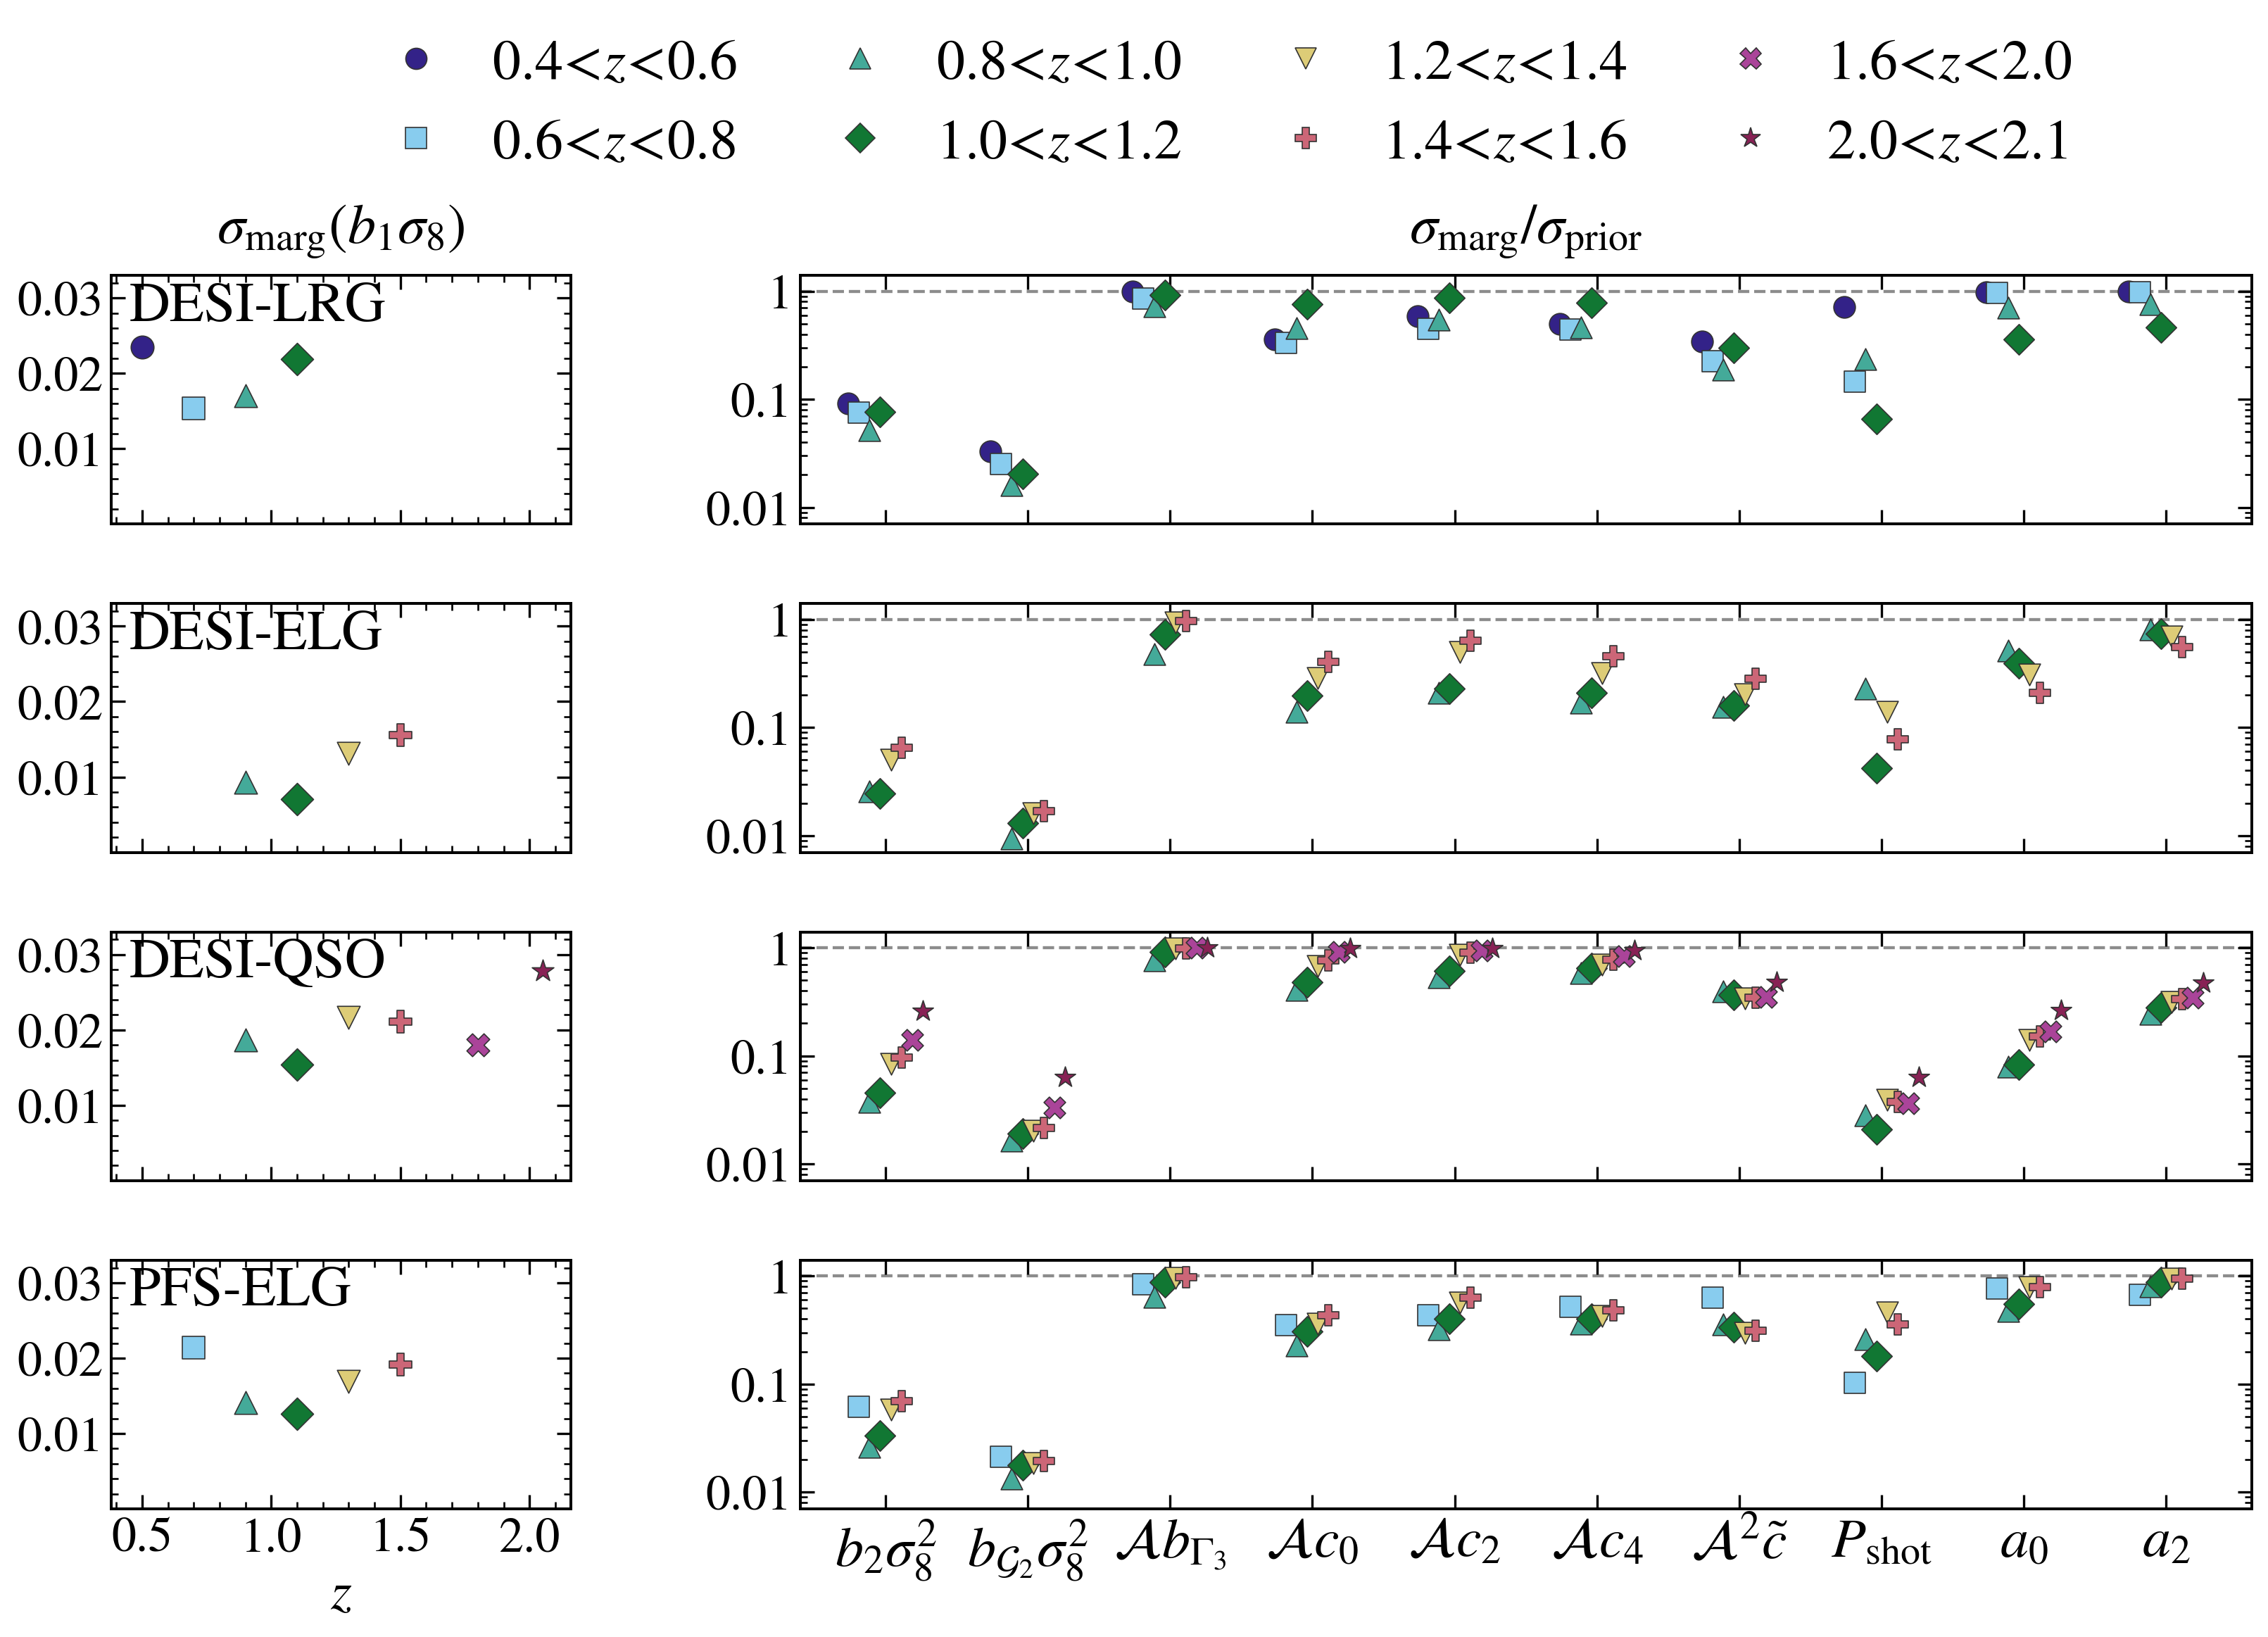

In [4]:
FIGSIZE = (14, 10)
fig, axes = plt.subplots(4, 2, figsize=FIGSIZE, sharex='col',
                         gridspec_kw={'width_ratios': [1.9, 6.]})
fig.subplots_adjust(left=.083, right=.988, bottom=.10, top=.83, hspace=.32, wspace=.24)
plotted_names1 = []
for i, tracer in enumerate(['DESI-LRG','DESI-ELG','DESI-QSO','PFS-ELG']):
    left, right = axes[i]
    available = sorted({int(r['nominal_bin']) for r in rows1 if r['tracer'] == tracer})
    for ib in available:
        rr = {r['coordinate']: r for r in rows1 if r['tracer'] == tracer and int(r['nominal_bin']) == ib}
        assert len(rr) == 11
        plotted_names1.extend(r['name'] for r in rr.values())
        left.scatter(float(rr['b1_sigma8']['z_model']), float(rr['b1_sigma8']['sigma_marginal']),
                     color=colors1[ib], marker=markers1[ib], s=95, edgecolors='.2', linewidths=.5, zorder=4)
        right.scatter(np.arange(10)+(ib-3.5)*.075,
                      [float(rr[c]['posterior_prior_ratio']) for c in coordinates1],
                      color=colors1[ib], marker=markers1[ib], s=85, edgecolors='.2', linewidths=.5, zorder=4)
    left.set(xlim=(.38,2.16), ylim=(0,.033))
    left.set_yticks([.01,.02,.03], ['0.01','0.02','0.03'])
    left.set_xticks([.5,1.,1.5,2.])
    left.text(.04,.82,tracer,transform=left.transAxes,fontsize=24)
    right.set(yscale='log', ylim=(.007,1.4), xlim=(-.6,9.6))  # CT-A: ELG-1 bG2 ratio 0.0093
    right.set_yticks([.01,.1,1], ['0.01','0.1','1'])
    right.yaxis.set_minor_formatter(NullFormatter())
    right.axhline(1, color=GREY, ls='--', lw=1.3, zorder=1)
    right.set_xticks(np.arange(10), labels1, fontsize=24)
    right.xaxis.set_minor_locator(mpl.ticker.NullLocator())
assert sorted(plotted_names1) == sorted(r['name'] for r in rows1)
axes[0,0].set_title(r'$\sigma_{\rm marg}(b_1\sigma_8)$', pad=14)
axes[0,1].set_title(r'$\sigma_{\rm marg}/\sigma_{\rm prior}$', pad=14)
axes[-1,0].set_xlabel(r'$z$')
handles = [Line2D([],[],ls='',marker=markers1[i],color=colors1[i],mec='.2',mew=.5,ms=9,
                  label=rf'${lo:.1f}\!<\!z\!<\!{hi:.1f}$') for i,(lo,hi) in enumerate(bins1)]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.55,1.), ncol=4,
           frameon=False, fontsize=24, columnspacing=1.2, handletextpad=.35)
save_figure(fig, 1)

## Figure 2 — cosmological uncertainties

The same absolute uncertainties as the manuscript table, shown as **points on
restricted vertical ranges** so that small differences remain visible. Unlike bars,
the points do not use their distance from zero to encode the errors. No normalization
or change to the forecast is made. These are standard deviations, not data measurements
requiring error bars.

| Case | Spectra and covariance |
|:--|:--|
| A | DESI auto-spectra with their mutual covariance (reference) |
| B | A plus DESI cross-spectra |
| C | B plus PFS auto-spectra |
| D | C plus DESI × PFS cross-spectra |

All share the same eight nominal bins and $k_{\max}=0.20\,h_{\rm ref}\,{\rm Mpc}^{-1}$.
PFS baseline support is $0.6\leq z\leq1.6$. $h,\omega_b,n_s$ are fixed.
All four cases retain the mutual Gaussian covariance of the measured spectra.

In [5]:
rows2 = {r['case']: r for r in read_csv('cosmological_constraints.csv') if r['group'] == 'shell304'}
assert set(rows2) == set(CASE_ORDER)
values2 = np.array([[float(rows2[c][q]) for q in QUANTITIES] for c in CASE_ORDER])
scales2 = np.array([1000.,1.,1000.])

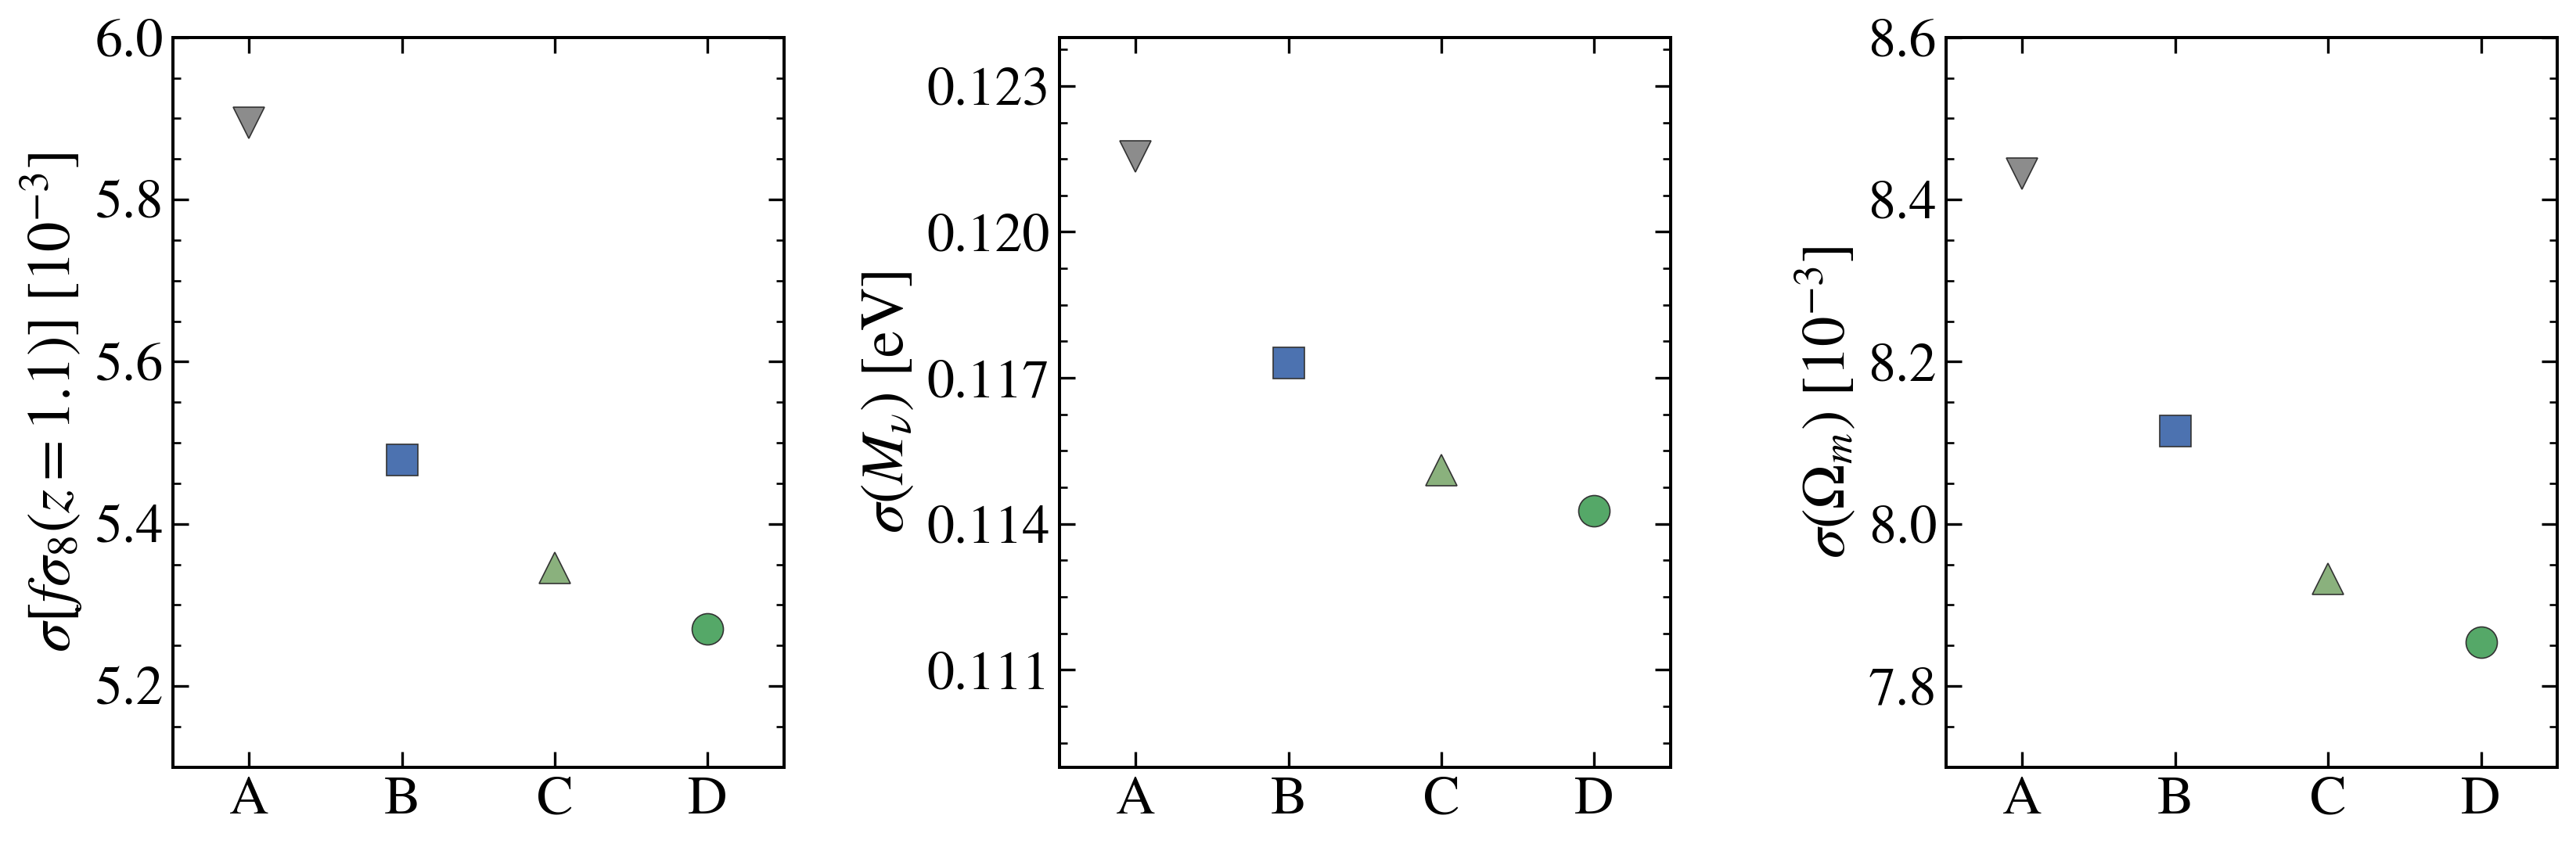

In [6]:
FIGSIZE = (14, 4.8)
YLIMS = [(5.1,6.0), (.109,.124), (7.7,8.6)]
YLABELS = [r'$\sigma[f\sigma_8(z=1.1)]\ [10^{-3}]$',
           r'$\sigma(M_\nu)\ [{\rm eV}]$', r'$\sigma(\Omega_m)\ [10^{-3}]$']
fig, axes = plt.subplots(1,3,figsize=FIGSIZE)
fig.subplots_adjust(left=.078,right=.985,bottom=.15,top=.96,wspace=.45)
for j,ax in enumerate(axes):
    for i,c in enumerate(CASE_ORDER):
        ax.plot(i,values2[i,j]*scales2[j],marker=CASE_MARKERS[c],color=CASE_COLORS[c],
                ls='none',ms=12,mec='.2',mew=.5)
    categorical_axis(ax,CASE_ORDER)
    ax.set(ylim=YLIMS[j],ylabel=YLABELS[j])
    ax.yaxis.set_major_locator(MaxNLocator(5))
save_figure(fig, 2)

## Figure 3 — nuisance marginalization penalty

$\sigma_{\rm marg}/\sigma_{\rm fixed}$ uses each case's **own** nuisance-fixed limit;
other cosmological parameters remain marginalized in both. Nuisances are fixed in
the revised sampling coordinates, including $b_1\sigma_8$, rather than $b_1$.
Unity means no penalty. This ratio is neither an additive information fraction nor
a comparison to one common ideal forecast. Keep the unity line when adjusting axes.
The three cosmological quantities share one panel, with a parameter legend.

In [7]:
rows3 = {(r['case'],r['quantity']):r for r in read_csv('nuisance_marginalization.csv')
         if r['group'] == 'shell304'}
values3 = np.array([[float(rows3[c,q]['penalty']) for q in QUANTITIES] for c in CASE_ORDER])
for (c,q),r in rows3.items():
    assert np.isclose(float(r['penalty']),float(r['sigma_marg'])/float(r['sigma_fixed']),rtol=1e-12)
assert np.all(values3 >= 1)

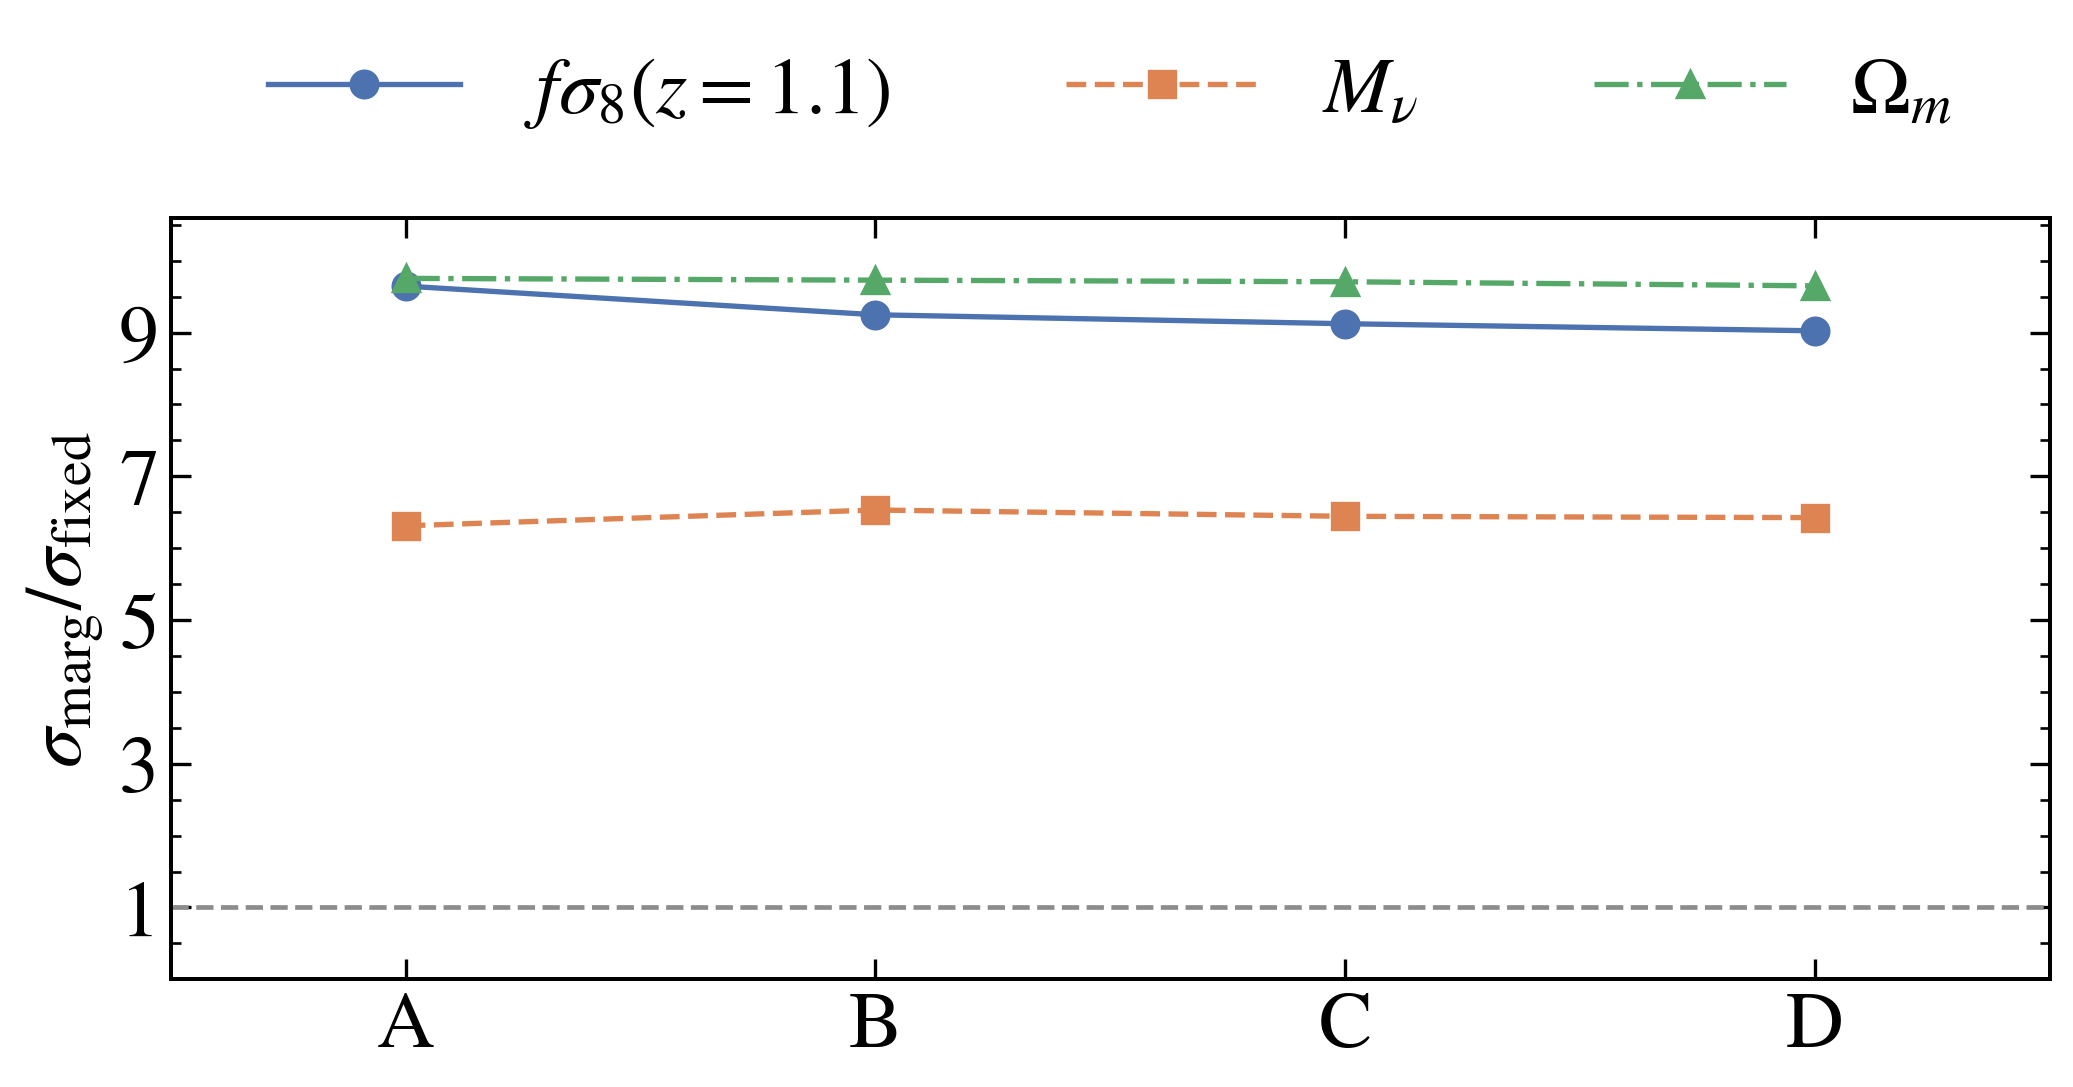

In [8]:
FIGSIZE = (9, 4.6)
with plt.rc_context({'font.size': 24, 'axes.labelsize': 24,
                     'xtick.labelsize': 24, 'ytick.labelsize': 24,
                     'legend.fontsize': 24}):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    fig.subplots_adjust(left=.11, right=.98, bottom=.15, top=.84)
    for j,(color,marker,style) in enumerate(zip([BLUE,ORANGE,GREEN],
                                               ['o','s','^'],['-','--','-.'])):
        ax.plot(np.arange(len(CASE_ORDER)),values3[:,j],color=color,marker=marker,
                ls=style,lw=1.6,ms=8,label=QUANTITY_LABELS[j])
    ax.axhline(1,color=GREY,ls='--',lw=1.4)
    categorical_axis(ax,CASE_ORDER)
    ax.set(ylim=(0,10.6),ylabel=r'$\sigma_{\rm marg}/\sigma_{\rm fixed}$')
    ax.set_yticks([1,3,5,7,9])
    ax.legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=3,
              frameon=False,handlelength=2.4,columnspacing=2.2)
    save_figure(fig, 3)

## Figure 4 — robustness of the incremental PFS contribution

Upper panels retain absolute B and D errors. Lower panels show
$100(1-\sigma_D/\sigma_B)$. Each alternative changes **one** assumption;
these are not a continuous parameter sweep. The vertical ranges below are the
previously approved tightened ranges. The baseline has $k_{\max}=0.20$;
$k_{\max}=0.15$ is in $h_{\rm ref}\,{\rm Mpc}^{-1}$. “Priors” scales finite
nuisance-prior standard deviations only. “No DR1 ELG1” removes the DESI DR1 ELG1 interval
$0.8\leq z<1.1$: all of forecast ELG-1 and the part of ELG-2 below $z=1.1$. Flat nuisance and cosmological priors are unchanged.

In [9]:
rows4 = {(r['variation'],r['quantity']):r for r in read_csv('pfs_gains.csv') if r['grid']=='shell304'}
variations4 = ['reference','k015','prior3','prior10','no_elg1']
labels4 = ['Ref.', '$k_{\\max}$\n$0.15$', 'Priors\n$\\times3$', 'Priors\n$\\times10$', 'No\nDR1\nELG1']
b4 = np.array([[float(rows4[v,q]['sigma_B']) for q in QUANTITIES] for v in variations4])
d4 = np.array([[float(rows4[v,q]['sigma_D']) for q in QUANTITIES] for v in variations4])
gain4 = np.array([[float(rows4[v,q]['gain_percent']) for q in QUANTITIES] for v in variations4])
np.testing.assert_allclose(gain4,100*(1-d4/b4),rtol=1e-12)
np.testing.assert_allclose(b4[0],values2[CASE_ORDER.index('B')],rtol=1e-12)
np.testing.assert_allclose(d4[0],values2[CASE_ORDER.index('D')],rtol=1e-12)

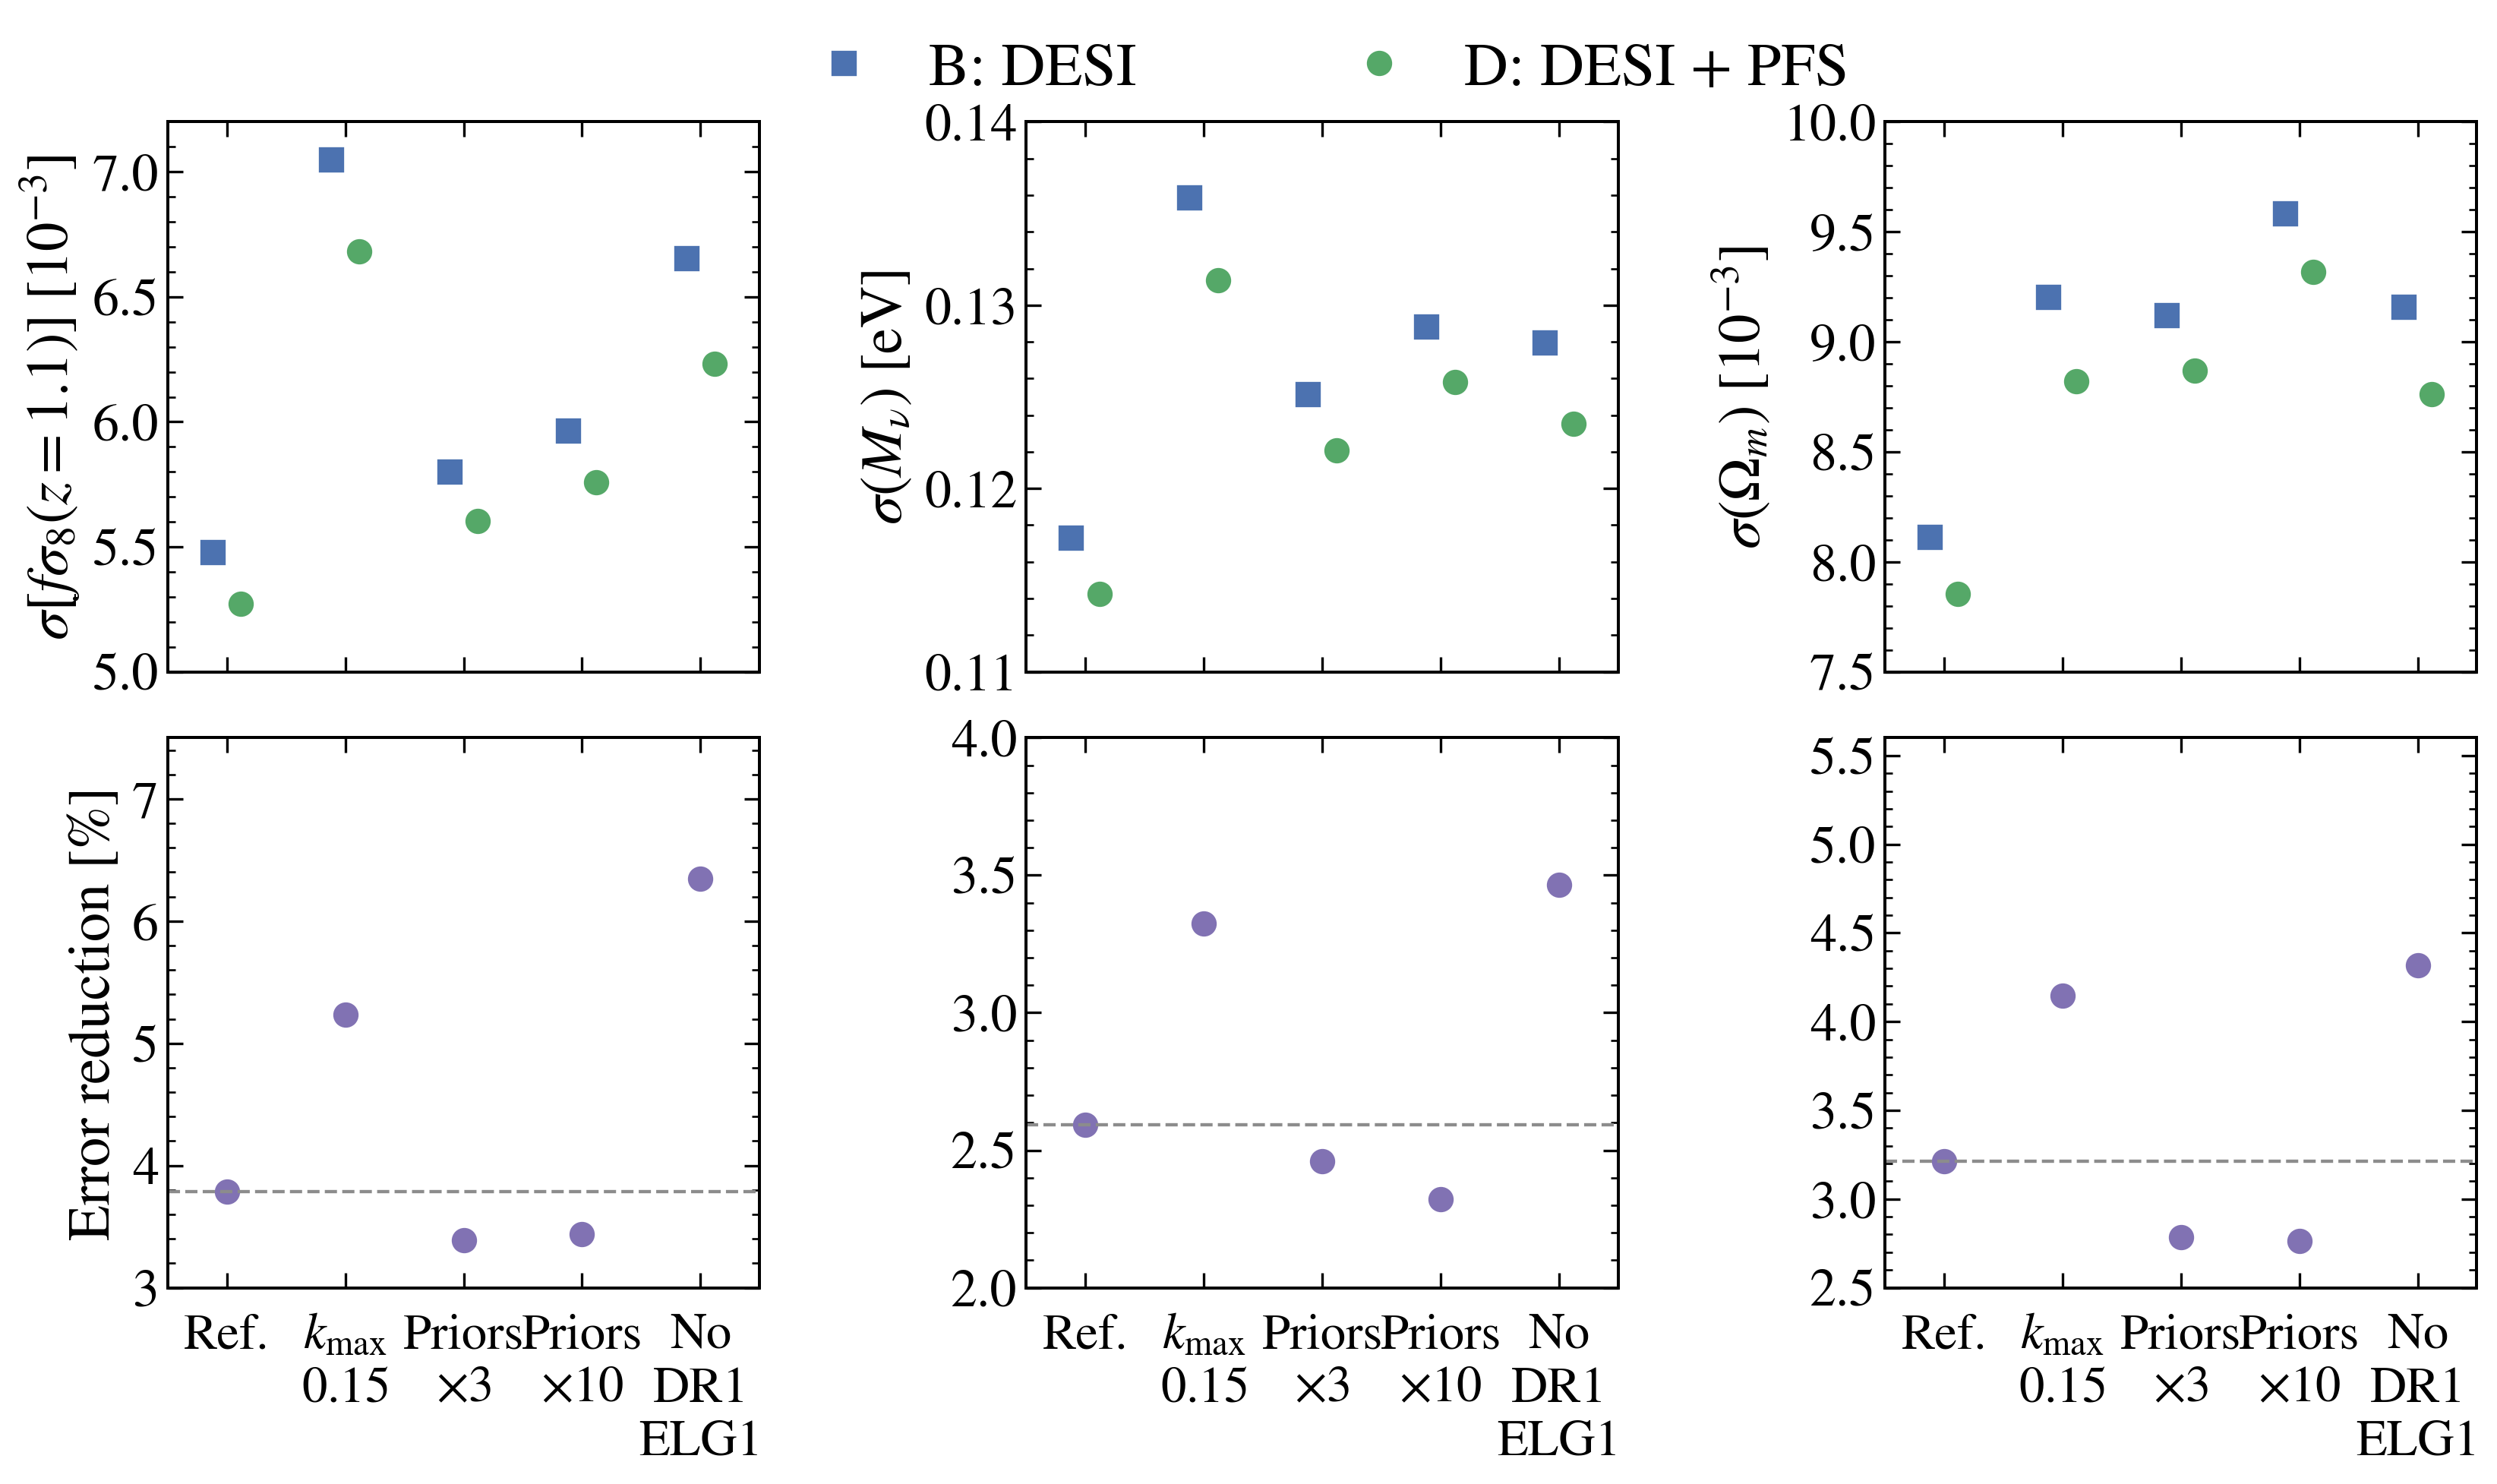

In [10]:
FIGSIZE = (14, 8.2)
SIGMA_LIMITS = [(5.,7.2),(.11,.14),(7.5,10.)]
SIGMA_TICKS = [[5.,5.5,6.,6.5,7.],[.11,.12,.13,.14],[7.5,8.,8.5,9.,9.5,10.]]
GAIN_TICKS = [[3.,4.,5.,6.,7.],[2.,2.5,3.,3.5,4.],[2.5,3.,3.5,4.,4.5,5.,5.5]]
GAIN_LIMITS = [(3.,7.5),(2.,4.),(2.5,5.6)]  # CT-A: prior x3/x10 Omega_m gains 2.78/2.76%
fig, axes = plt.subplots(2,3,figsize=FIGSIZE,sharex='col')
fig.subplots_adjust(left=.08,right=.985,bottom=.13,top=.91,wspace=.45,hspace=.12)
x = np.arange(len(variations4))
for j in range(3):
    top,bottom = axes[:,j]
    #for i in x:
        #top.plot([i-.12,i+.12],np.array([b4[i,j],d4[i,j]])*scales2[j],color=GREY,lw=1.2)
    top.plot(x-.12,b4[:,j]*scales2[j],ls='none',marker='s',ms=9,color=BLUE,label='B: DESI')
    top.plot(x+.12,d4[:,j]*scales2[j],ls='none',marker='o',ms=9,color=GREEN,label='D: DESI + PFS')
    top.set(ylim=SIGMA_LIMITS[j],ylabel=YLABELS[j])
    top.set_yticks(SIGMA_TICKS[j])
    bottom.plot(x,gain4[:,j],ls='none',marker='o',ms=9,color='#8172B3')
    bottom.axhline(gain4[0,j],color=GREY,ls='--',lw=1.3)
    bottom.set_ylim(GAIN_LIMITS[j]);bottom.set_yticks(GAIN_TICKS[j])
    categorical_axis(bottom,labels4)
    bottom.tick_params(axis='x',labelsize=20,pad=10)
axes[1,0].set_ylabel('Error reduction [%]')
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='upper center',bbox_to_anchor=(.53,1.),
           ncol=2,frameon=False,columnspacing=3,handletextpad=.4,fontsize=24)
save_figure(fig, 4)

## Figure 5 — joint cosmology–bias contours

Full marginalized covariances for A, B and D. The bias is ELG-1 $b_1\sigma_8$
for $0.8\leq z<1.0$, evaluated at $z=0.9$; the derived growth quantity is $f\sigma_8(z=1.1)$. Axes show deviations
from the common fiducials, with the explicit scale factors below.

For **joint two-dimensional** 68% and 95% Gaussian contours use
$\Delta\chi^2=-2\ln(1-p)$, not one-dimensional $1\sigma$ and $2\sigma$ radii.
Solid curves indicate 68%; dashed curves indicate 95%. Negative mass offsets are
allowed: these local Gaussian forecasts do not impose the physical mass boundary.
All contours are unfilled. Grey, blue and green match the original Figure 5
(`figures.ipynb`): A, B and D, respectively.

In [11]:
covariances5 = json.loads((DATA_DIR/'selected_covariances.json').read_text())
scales5 = np.array([100.,1.,1000.])
pairs5 = [(0,1),(0,2),(2,1)]
probabilities5 = np.array([.68,.95])
thresholds5 = -2*np.log1p(-probabilities5)
for case in ['A','B','D']:
    record = covariances5['shell304/'+case]
    assert record['labels'] == ['bin02:DESI-ELG:b1_sigma8','Mnu','fsigma8_z1p1']
    assert record['beta_model_redshift'] == .9 and record['beta_nominal_bin'] == [.8,1.]
    assert record['growth_report_redshift'] == 1.1
    cov = np.array(record['covariance'])
    np.testing.assert_allclose(cov,cov.T,rtol=1e-12,atol=1e-15)
    assert np.linalg.eigvalsh(cov).min() > 0
    np.testing.assert_allclose(np.sqrt(np.diag(cov))[1:],
                               [float(rows2[case]['Mnu_eV']),float(rows2[case]['fsigma8_z1p1'])],rtol=1e-12)

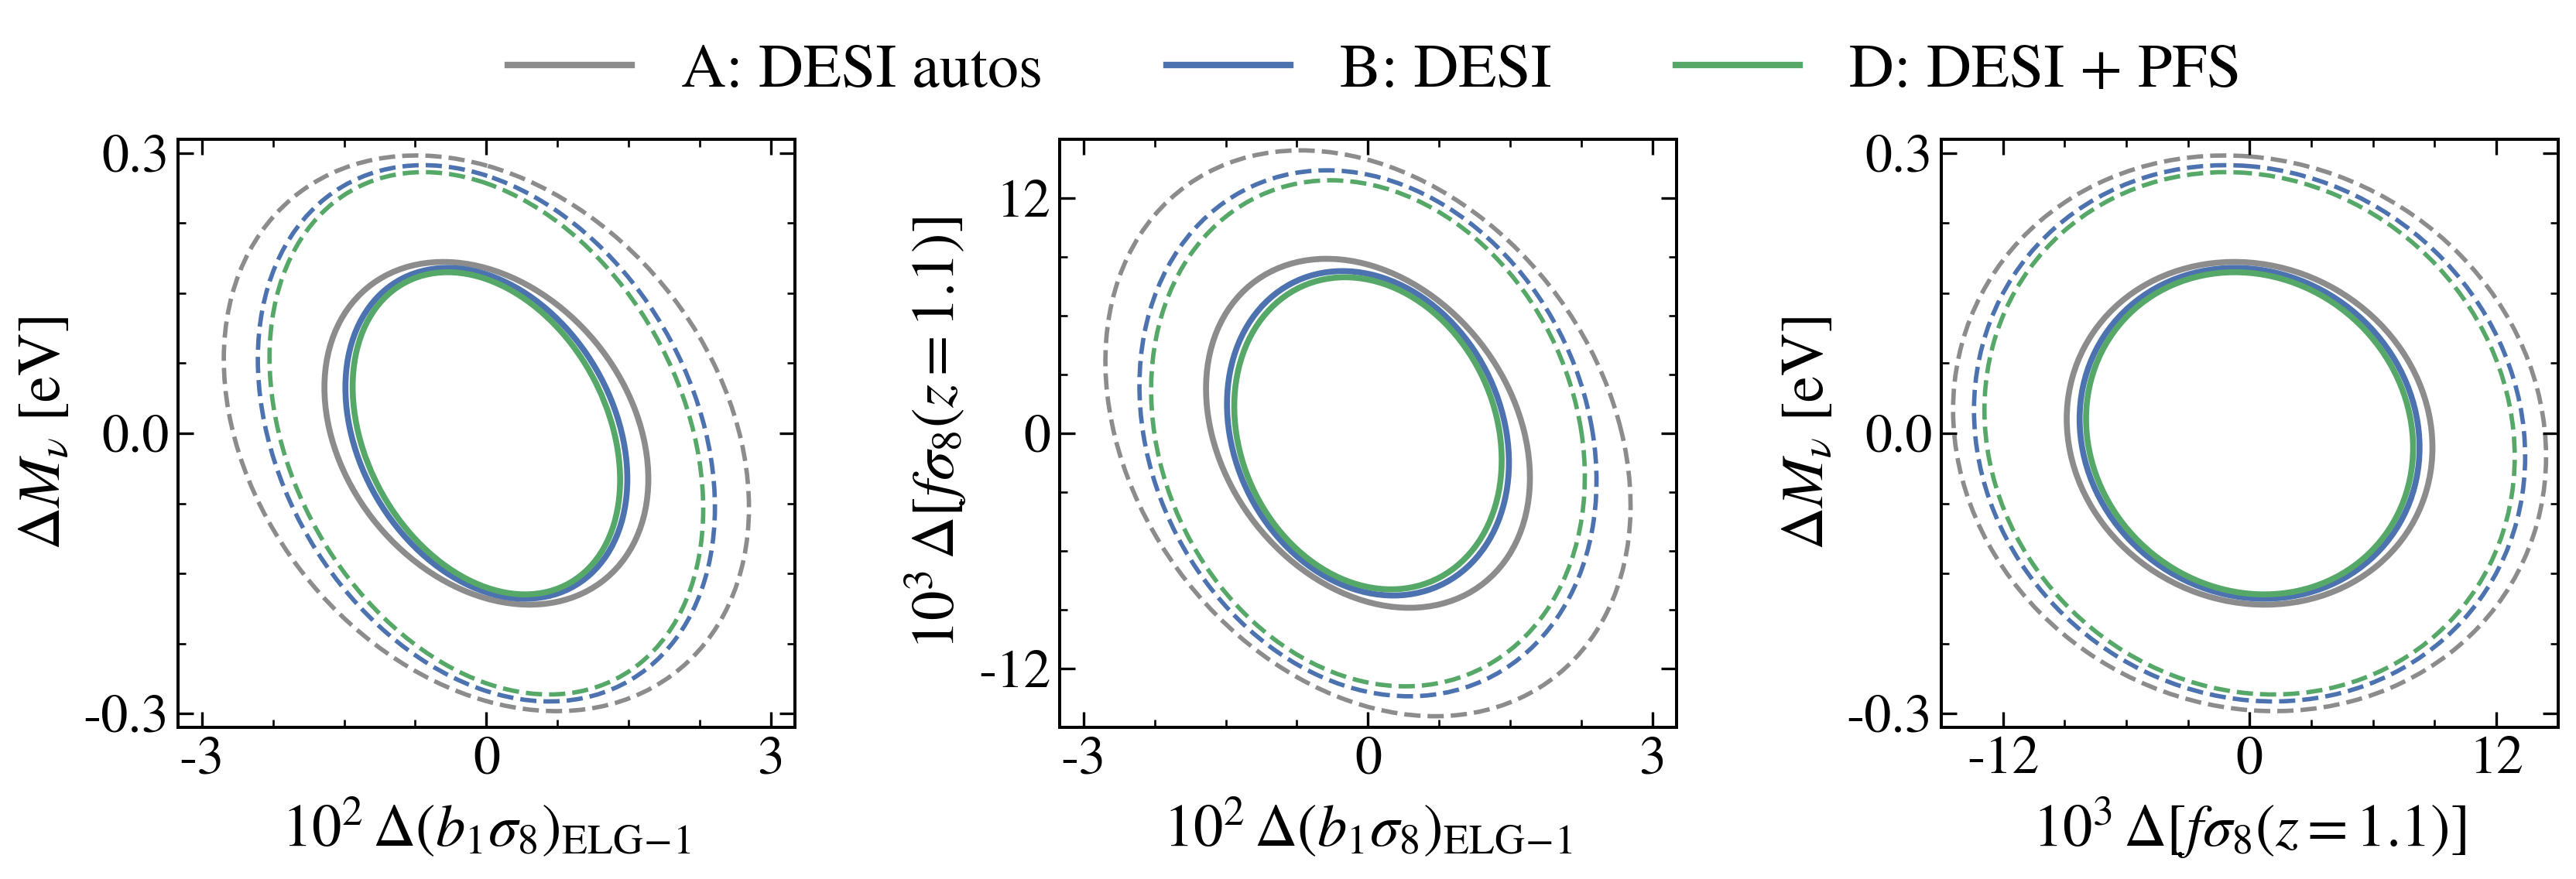

In [12]:
FIGSIZE = (14, 4.8)
COLORS5 = dict(A=GREY, B=BLUE, D=GREEN)
LIMITS = [(-3.25,3.25),(-.315,.315),(-15.,15.)]
TICKS = [[-3,0,3],[-.3,0,.3],[-12,0,12]]
LABELS = [r'$10^2\,\Delta(b_1\sigma_8)_{\mathrm{ELG\! -\! 1}}$',r'$\Delta M_\nu\ [{\rm eV}]$',
          r'$10^3\,\Delta[f\sigma_8(z=1.1)]$']
fig, axes = plt.subplots(1,3,figsize=FIGSIZE)
fig.subplots_adjust(left=.07,right=.985,bottom=.19,top=.85,wspace=.43)
contours5 = []
for ax,(ix,iy) in zip(axes,pairs5):
    for case in ['A','B','D']:
        c = np.array(covariances5['shell304/'+case]['covariance'])*scales5[:,None]*scales5[None,:]
        c2 = c[np.ix_([ix,iy],[ix,iy])]
        eig,vec = np.linalg.eigh(c2)
        angle = np.degrees(np.arctan2(vec[1,1],vec[0,1]))
        for prob,threshold in reversed(list(zip(probabilities5,thresholds5))):
            widths = 2*np.sqrt(threshold*eig[::-1])
            extent = np.sqrt(threshold*np.diag(c2))
            assert extent[0] < LIMITS[ix][1] and extent[1] < LIMITS[iy][1]
            ax.add_patch(Ellipse((0,0),*widths,angle=angle,fill=False,edgecolor=COLORS5[case],
                                 lw=2.3 if prob==.68 else 1.7,ls='-' if prob==.68 else '--'))
            contours5.append({'case':case,'plane':[ix,iy],'probability':float(prob),
                              'delta_chi2':float(threshold),'widths':widths.tolist(),'angle':float(angle)})
    ax.set(xlim=LIMITS[ix],ylim=LIMITS[iy],xlabel=LABELS[ix],ylabel=LABELS[iy])
    ax.set_xticks(TICKS[ix]);ax.set_yticks(TICKS[iy])
fig.legend(handles=[Line2D([],[],color=COLORS5[c],lw=2.5,label=lab) for c,lab in
                    [('A','A: DESI autos'),('B','B: DESI'),('D','D: DESI + PFS')]],
           loc='upper center',bbox_to_anchor=(.53,1.02),ncol=3,frameon=False,fontsize=24)
save_figure(fig, 5)

## Figure 6 — derivative diagnostics

Representative ELG-1 auto-spectrum at $z=0.9$, 304 shells and multipoles
$\ell=0,2,4$. Left: $|s_i\partial P_0/\partial\theta_i|/|P_0|$, with the **largest
checked small step**, not a prior-width rescaling. This is not a ranking of physical
parameter importance. The vanishing $c_2,c_4$ monopole responses are omitted from the
logarithmic panel only; all 14 coordinates remain in the right panel.

Right: covariance-weighted relative discrepancies between automatic differentiation
and symmetric finite differences, for $s_i,s_i/2,s_i/4$. All are below $10^{-3}$.
The source uses the scaled nuisance coordinates specified in the manuscript;
short labels omit the explicit $\mathcal{A}$ factors shown in its parameter table.
For these derivatives the held-fixed coordinates are the amplitude-scaled ones.
This is a saved representative-cell check, not a new validation of every cosmology.

In [13]:
data6 = read_npz('fig6_data.npz')
k6,response6,error6 = data6['k'],data6['response'],data6['fd_error']
labels6 = [r'$\ln(10^{10}A_s)$',r'$M_\nu$',r'$\Omega_m$',r'$b_1\sigma_8$',r'$b_2\sigma_8^2$',
           r'$b_{\mathcal{G}_2}\sigma_8^2$',r'$b_{\Gamma_3}$',r'$c_0$',r'$c_2$',r'$c_4$',
           r'$\tilde{c}$',r'$P_{\rm shot}$',r'$a_0$',r'$a_2$']
assert response6.shape == (304,14) and error6.shape == (14,3)
assert np.all(error6 < 1e-3) and np.all(error6 > 0)
zero6 = np.max(response6,axis=0) < 1e-12
assert [n.split(':')[-1] for n in data6['names'][zero6]] == ['c2','c4']
print('Finite-difference steps by coordinate:',dict(zip(data6['names'],data6['steps'][:,0])))

Finite-difference steps by coordinate: {np.str_('ln10_10_As'): np.float64(0.001), np.str_('Mnu'): np.float64(0.005), np.str_('Omegam'): np.float64(0.001), np.str_('bin02:DESI-ELG:b1_sigma8'): np.float64(0.001), np.str_('bin02:DESI-ELG:b2_sigma8sq'): np.float64(0.001), np.str_('bin02:DESI-ELG:bG2_sigma8sq'): np.float64(0.001), np.str_('bin02:DESI-ELG:bGamma3'): np.float64(0.001), np.str_('bin02:DESI-ELG:c0'): np.float64(0.001), np.str_('bin02:DESI-ELG:c2'): np.float64(0.03), np.str_('bin02:DESI-ELG:c4'): np.float64(0.001), np.str_('bin02:DESI-ELG:c_tilde'): np.float64(0.4), np.str_('bin02:DESI-ELG:Pshot'): np.float64(0.001), np.str_('bin02:DESI-ELG:a0'): np.float64(0.001), np.str_('bin02:DESI-ELG:a2'): np.float64(0.001)}


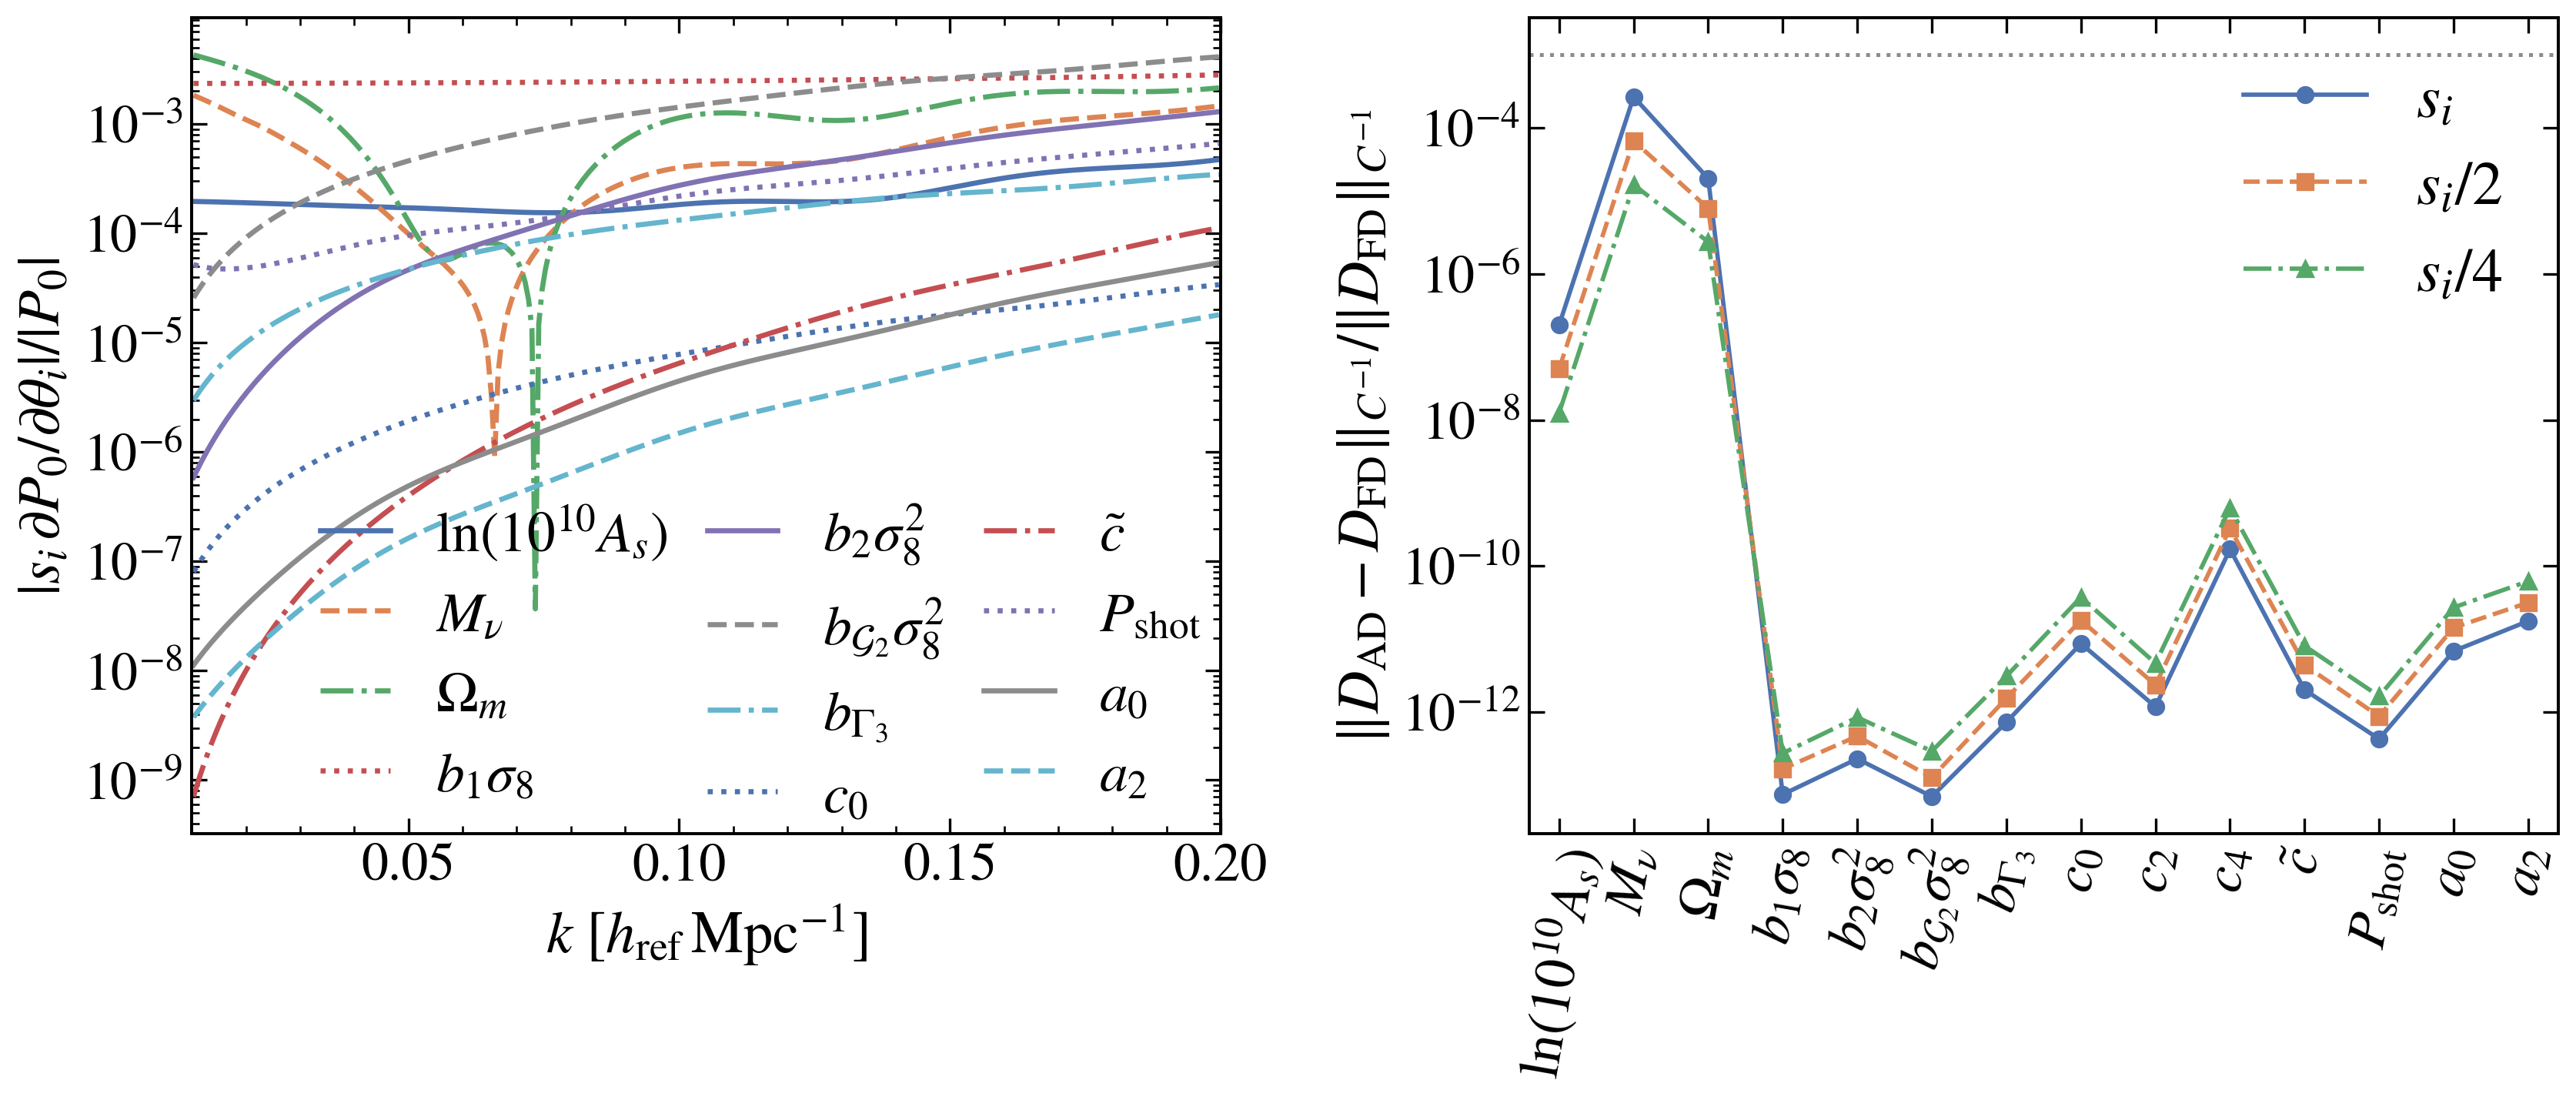

In [14]:
FIGSIZE = (14, 6.4)
COLORS = [BLUE,ORANGE,GREEN,RED,'#8172B3',GREY,'#64B5CD']
STYLES = ['-','--','-.',':']
fig, axes = plt.subplots(1,2,figsize=FIGSIZE)
fig.subplots_adjust(left=.073,right=.988,bottom=.27,top=.96,wspace=.30)
for j,label in enumerate(labels6):
    if zero6[j]:
        continue
    axes[0].semilogy(k6,response6[:,j],color=COLORS[j%7],ls=STYLES[j%4],lw=2,label=label)
axes[0].set(xlabel=K_LABEL,ylabel=r'$|s_i\,\partial P_0/\partial\theta_i|/|P_0|$',xlim=(.01,.2))
axes[0].legend(ncol=3,frameon=False,fontsize=22,handlelength=1.25,columnspacing=.7,loc='lower left',bbox_to_anchor=(0.075, -0.05),)
for s,(marker,ls,color) in enumerate(zip(['o','s','^'],['-','--','-.'],[BLUE,ORANGE,GREEN])):
    axes[1].semilogy(np.arange(14),error6[:,s],marker=marker,ls=ls,lw=1.7,ms=6,
                     color=color,label=[r'$s_i$',r'$s_i/2$',r'$s_i/4$'][s])
axes[1].axhline(1e-3,color=GREY,ls=':',lw=1.5)
axes[1].set_xticks(np.arange(14),labels6,rotation=80,ha='center',fontsize=22)
axes[1].xaxis.set_minor_locator(mpl.ticker.NullLocator())
axes[1].set(ylabel=r'$\|D_{\rm AD}-D_{\rm FD}\|_{C^{-1}}/\|D_{\rm FD}\|_{C^{-1}}$',xlim=(-.4,13.4))
axes[1].legend(frameon=False,loc='upper right',fontsize=24)
save_figure(fig, 6)

## Figure 7 — Gaussian covariance diagnostics

ELG-1 and PFS-ELG-2 occupy the common $0.8\leq z<1.0$ interval
in the $1200\,{\rm deg}^2$ overlap, evaluated at $z=0.9$. Left: monopole variances. Right: maximum normalized covariance discrepancy
over the nine auto/cross multipoles, comparing 64-point angular quadrature to a
Wigner-$3j$ expansion with the displayed $L_{\max}$ truncation. This checks numerical
angular integration and its normalization; it does not validate a Gaussian covariance
against non-Gaussian simulations. The input spectra and shell widths are unchanged.

In [15]:
data7 = read_npz('fig7_data.npz')
k7,cov7,error7 = data7['k'],data7['covariance'],data7['wigner_error']
assert cov7.shape == (304,9,9) and error7.shape == (3,304)
assert np.all(np.diagonal(cov7,axis1=1,axis2=2) > 0)
assert error7[2].max() < 1e-10

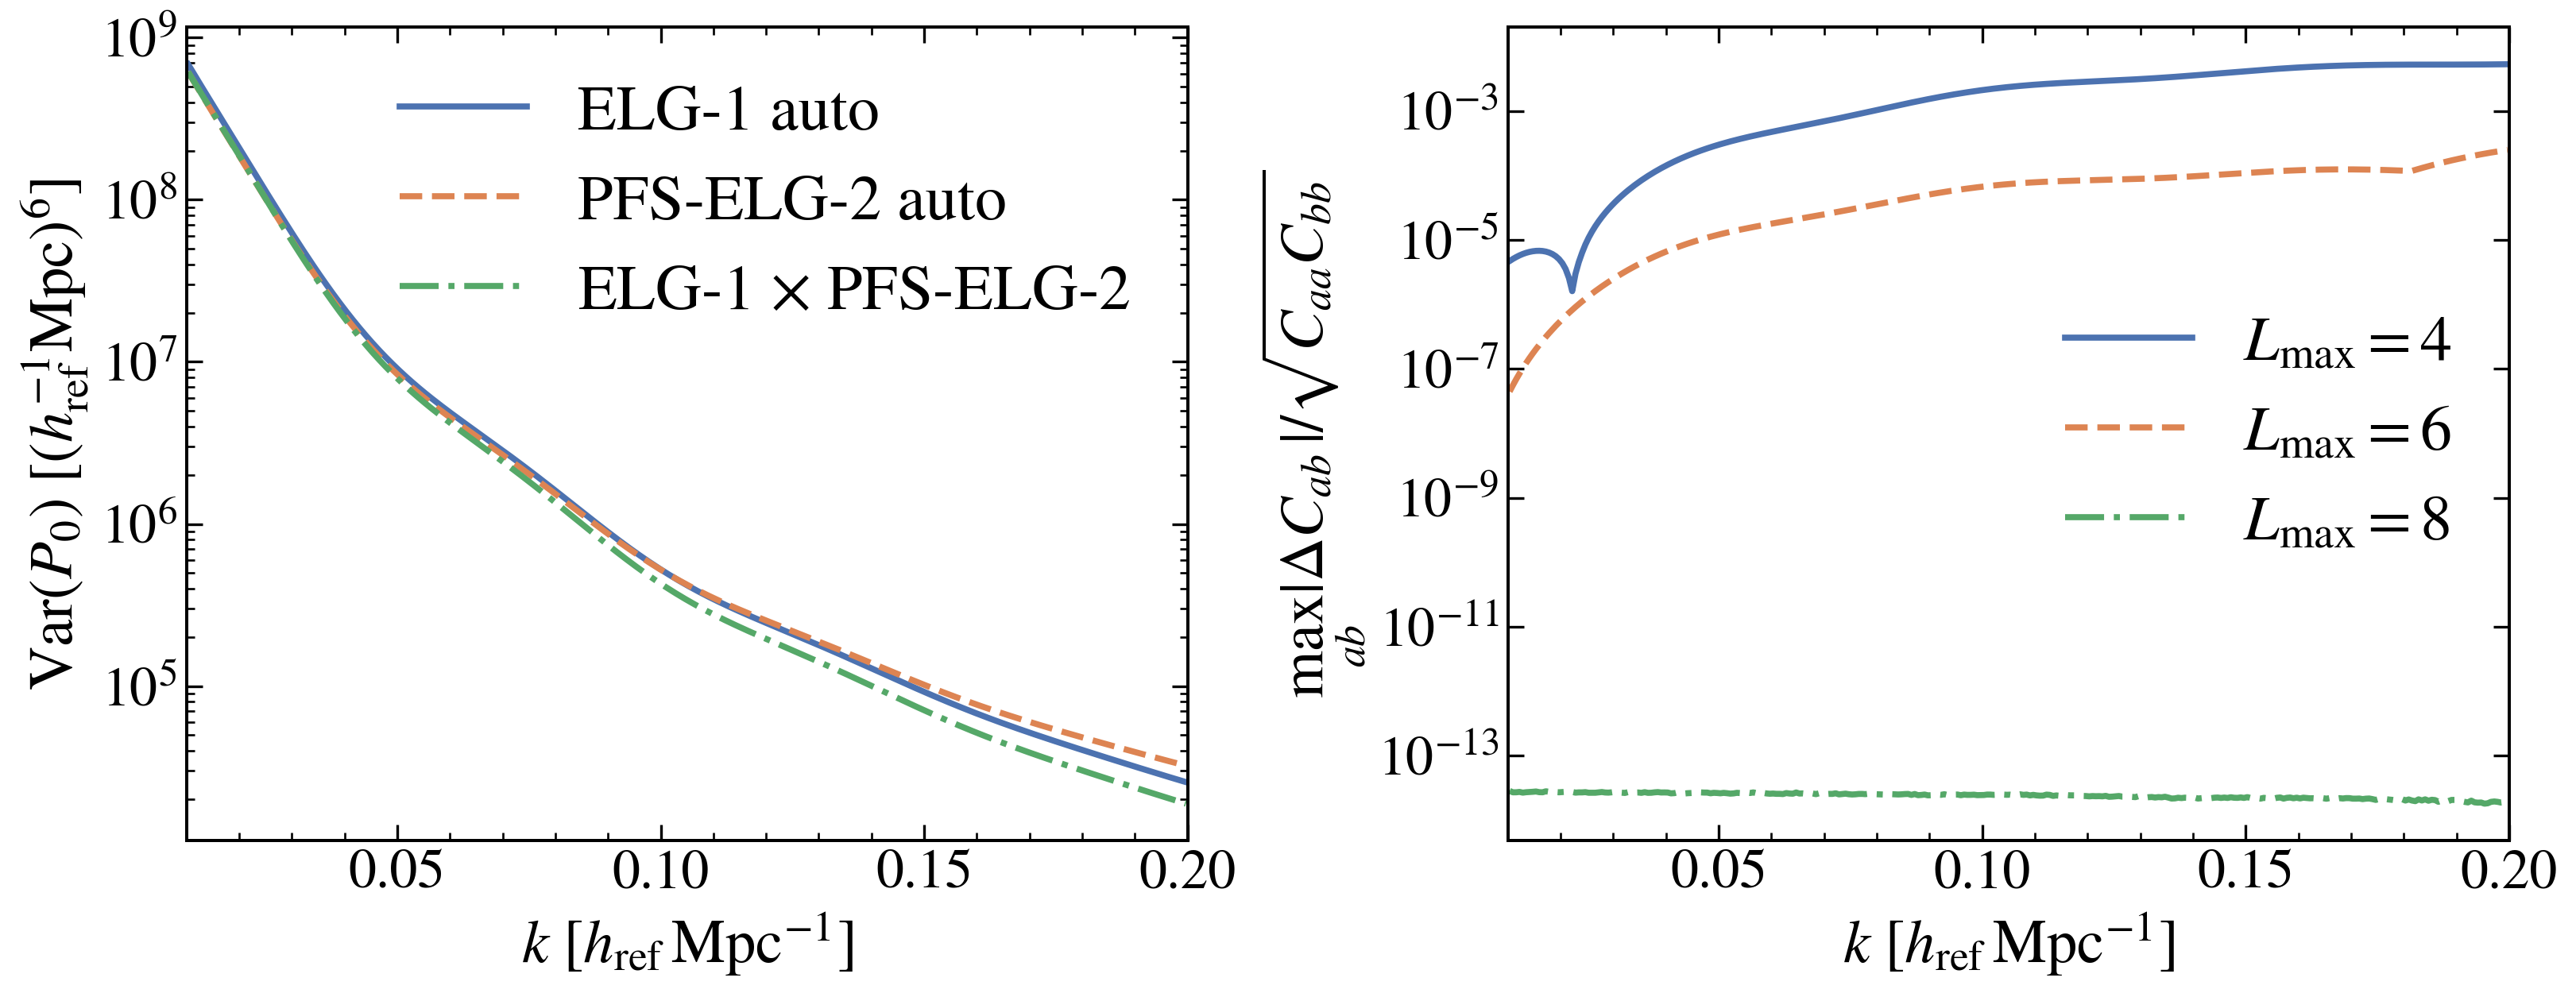

In [16]:
FIGSIZE = (14, 5.4)
fig, axes = plt.subplots(1,2,figsize=FIGSIZE)
fig.subplots_adjust(left=.09,right=.96,bottom=.17,top=.96,wspace=.32)
for j,(idx,label) in enumerate([(0,'ELG-1 auto'),(3,'PFS-ELG-2 auto'),(6,r'ELG-1 $\times$ PFS-ELG-2')]):
    axes[0].semilogy(k7,cov7[:,idx,idx],color=[BLUE,ORANGE,GREEN][j],
                     ls=['-','--','-.'][j],lw=2.3,label=label)
for j,lmax in enumerate([4,6,8]):
    axes[1].semilogy(k7,error7[j],color=[BLUE,ORANGE,GREEN][j],
                     ls=['-','--','-.'][j],lw=2.3,label=rf'$L_{{\max}}={lmax}$')
axes[0].set_ylabel(r'${\rm Var}(P_0)\ [(h_{\rm ref}^{-1}{\rm Mpc})^6]$')
axes[1].set_ylabel(r'$\max_{ab}|\Delta C_{ab}|/\sqrt{C_{aa}C_{bb}}$')
for ax in axes:
    ax.set(xlabel=K_LABEL,xlim=(.01,.2))
    ax.legend(frameon=False,fontsize=24)
save_figure(fig, 7)

## Figure 8 — matter-amplitude sample-variance limit

Analytic Kaiser diagnostic, **not a survey forecast**. The growth rate is fixed at
$f=0.8$; biases are marginalized. One tracer (solid) is compared with two tracers
(dashed), with equal number densities and independent Poisson noise. The two-tracer
matter-amplitude variance tends to $2/N_{\rm modes}$, rather than zero.
The unused third saved column holds $b_B$ fixed and is deliberately not plotted.

$P_m=10^3\,(h_{\rm ref}^{-1}{\rm Mpc})^3$, $b_A=1$, $b_B=2$,
$k=0.1\,h_{\rm ref}\,{\rm Mpc}^{-1}$, $\Delta k=0.01\,h_{\rm ref}\,{\rm Mpc}^{-1}$,
$V=10^9\,(h_{\rm ref}^{-1}{\rm Mpc})^3$; $N_{\rm modes}$ counts both signs of the wavevector.

In [17]:
data8 = read_npz('fig8_data.npz')
nbar8,variance8,floor8 = data8['nbar'],data8['relative_variance'],float(data8['floor'])
assert variance8.shape == (180,3)
np.testing.assert_allclose(floor8,2/(.1**2*.01*1e9/(2*np.pi**2)),rtol=1e-12)
assert np.all(variance8[:,1] >= floor8*(1-1e-9))
assert np.all(variance8[:,1] < variance8[:,0])

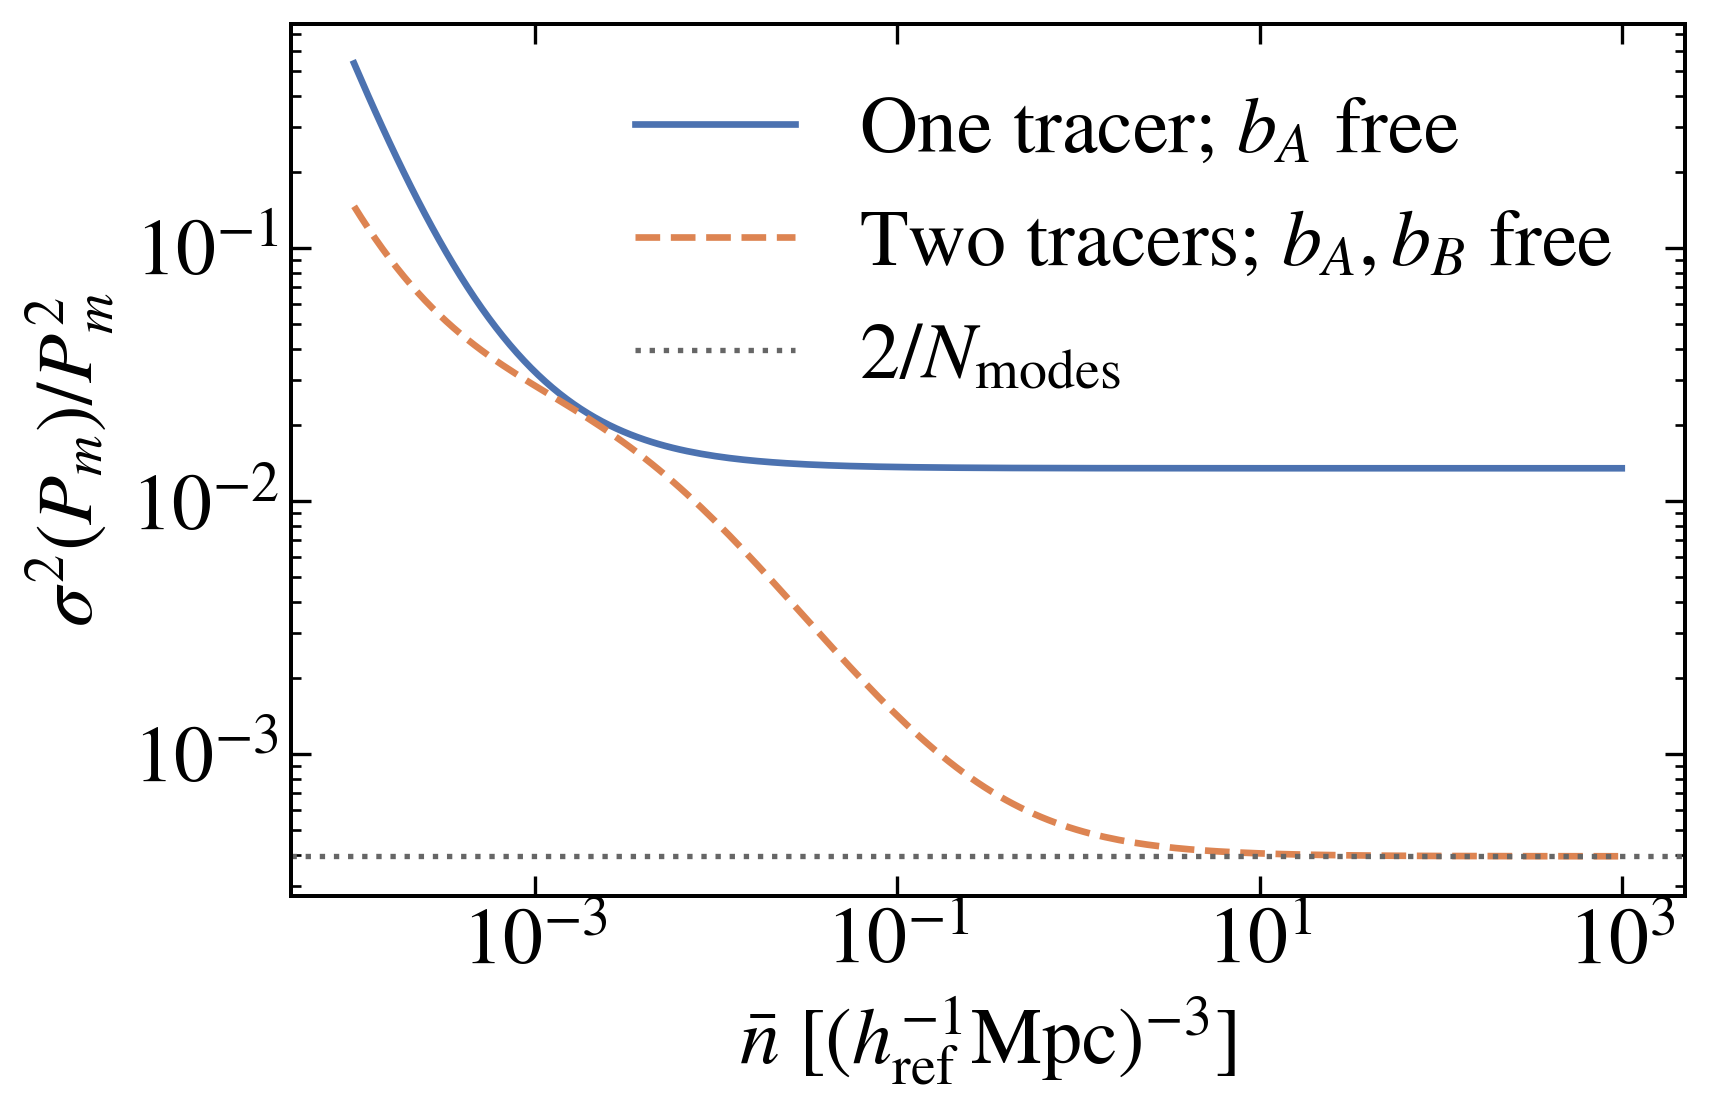

In [18]:
FIGSIZE = (7, 4.6)
with plt.rc_context({'font.size':24,'axes.labelsize':24,'xtick.labelsize':24,
                     'ytick.labelsize':24,'legend.fontsize':24}):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    fig.subplots_adjust(left=.15,right=.98,bottom=.18,top=.97)
    ax.loglog(nbar8,variance8[:,0],color=BLUE,lw=2,ls='-',label=r'One tracer; $b_A$ free')
    ax.loglog(nbar8,variance8[:,1],color=ORANGE,lw=2,ls='--',label=r'Two tracers; $b_A,b_B$ free')
    ax.axhline(floor8,color='.4',lw=1.6,ls=':',label=r'$2/N_{\rm modes}$')
    ax.set(xlabel=r'$\bar n\ [(h_{\rm ref}^{-1}{\rm Mpc})^{-3}]$',ylabel=r'$\sigma^2(P_m)/P_m^2$')
    ax.legend(frameon=False,loc='upper right')
    save_figure(fig, 8)

## Figure 9 — accumulated cosmological constraints

ELG-1 auto-multipoles at $z=0.9$ over the full DESI area. At each upper cut,
all shells from $k_{\min}=0.01$ are included and each prior enters **once**.
The other cosmological coordinates are marginalized in **both** curves.
The derived growth redshift is **0.9 here**, unlike the global headline value at 1.1.

The ordinate is an inverse accumulated variance, not $dF/dk$ or an additive
marginalized information density. Displayed upper cuts start at $0.03$; the retained
shells still start at $0.01$, in $h_{\rm ref}\,{\rm Mpc}^{-1}$.
Saved shell Fisher matrices and priors are bundled for provenance but are not
reinverted by this plotting notebook.

In [19]:
data9 = read_npz('fig9_data.npz')
kmax9,free9,fixed9 = data9['kmax'],data9['variance_free'],data9['variance_fixed']
assert free9.shape == fixed9.shape == (273,3)
assert np.all(free9 >= fixed9*(1-1e-8)) and np.all(fixed9 > 0)
assert np.all(np.diff(1/free9,axis=0) >= -1e-7)
print('Nuisance-induced variance ratios at kmax=0.20:', free9[-1]/fixed9[-1])

Nuisance-induced variance ratios at kmax=0.20: [ 78.53455201  35.58709194 147.21133882]


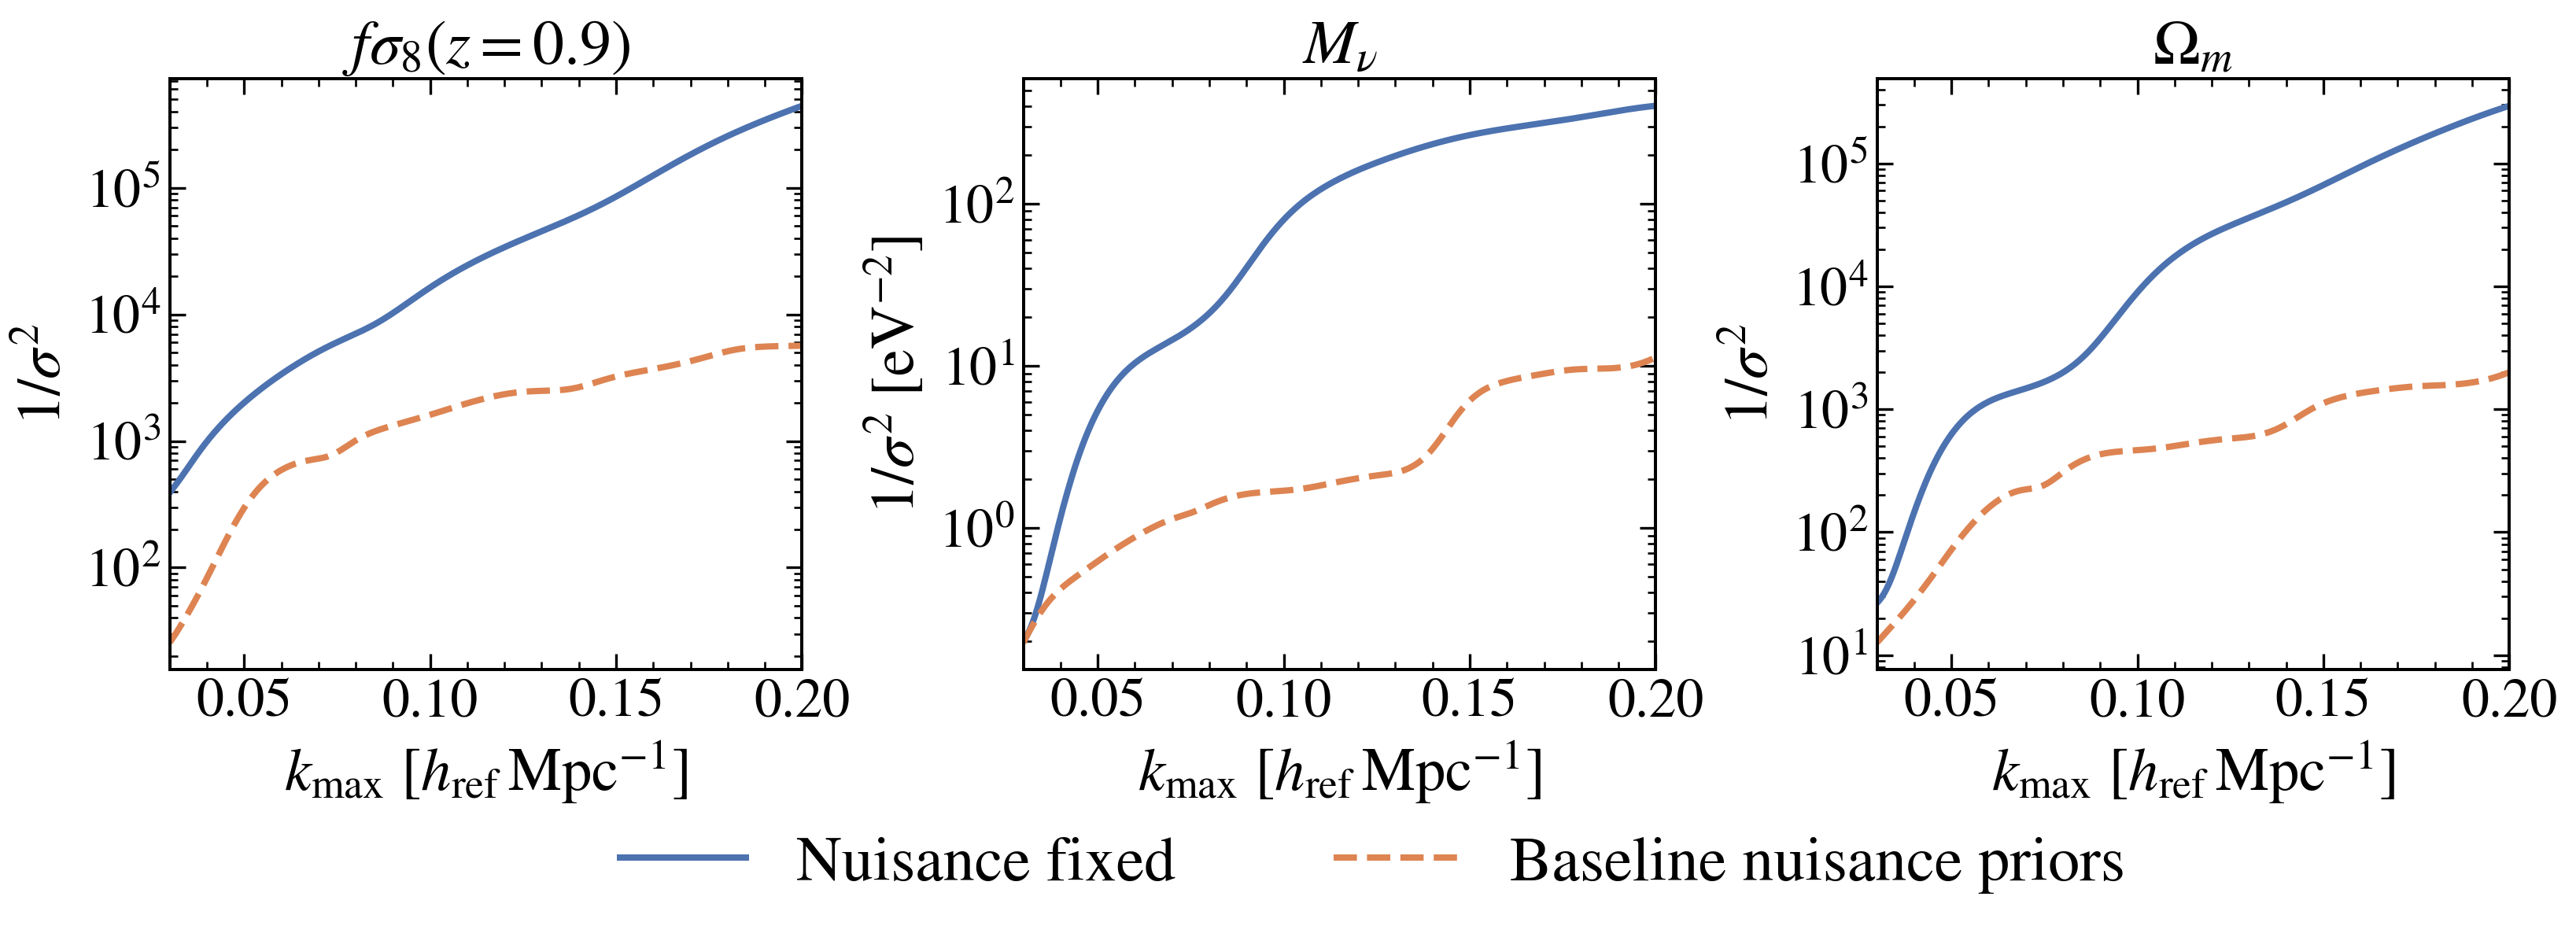

In [20]:
FIGSIZE = (14, 5.3)
fig, axes = plt.subplots(1,3,figsize=FIGSIZE)
fig.subplots_adjust(left=.075,right=.96,bottom=.28,top=.87,wspace=.35)
for j,(ax,label) in enumerate(zip(axes,[r'$f\sigma_8(z=0.9)$',r'$M_\nu$',r'$\Omega_m$'])):
    ax.semilogy(kmax9,1/fixed9[:,j],color=BLUE,ls='-',lw=2.4,label='Nuisance fixed')
    ax.semilogy(kmax9,1/free9[:,j],color=ORANGE,ls='--',lw=2.4,label='Baseline nuisance priors')
    ax.set(xlabel=r'$k_{\max}\ [h_{\rm ref}\,{\rm Mpc}^{-1}]$',title=label,
           ylabel=r'$1/\sigma^2$'+(r'$\ [{\rm eV}^{-2}]$' if j==1 else ''),xlim=(.03,.2))
    ax.set_xticks([.05,.1,.15,.2])
fig.legend(*axes[0].get_legend_handles_labels(),loc='lower center',bbox_to_anchor=(.53,0.),
           ncol=2,frameon=False,fontsize=24,columnspacing=2.5)
save_figure(fig, 9)

## Export record

This last cell records the input and output checksums and the Python/NumPy/Matplotlib
versions for this rendering. Its assertions concern the saved inputs and the nine
exports; they do not replace the numerical qualification of the forecast.

The source locations and their checksums are in `data/author_revision/manifest.json`.
`appendix_verification.json` preserves the existing diagnostic results and their
underlying numerical source identities. See `data/author_revision/README.md` for the
complete figure–data mapping and environment used for the checked notebook execution.

In [21]:
if EXPORT:
    assert set(export_records) == set(FIGURE_NAMES), 'Run all nine figure cells before recording a complete export.'
    report = {
        'notebook': 'notebooks/figures_author_revision.ipynb',
        'python': sys.version, 'platform': platform.platform(),
        'numpy': np.__version__, 'matplotlib': mpl.__version__,
        'input_manifest_sha256': hashlib.sha256((DATA_DIR/'manifest.json').read_bytes()).hexdigest(),
        'figures': [export_records[i] for i in range(1,10)],
        'checks': {'case_D_nuisance_values': len(plotted_names1),
                   'figure5_contours': len(contours5),
                   'joint_contour_delta_chi2': thresholds5.tolist(),
                   'figure6_max_discrepancy': float(error6.max()),
                   'figure7_L8_max_discrepancy': float(error7[2].max()),
                   'figure8_two_tracer_variance_over_floor': float(variance8[-1,1]/floor8),
                   'figure9_variance_ratios': (free9[-1]/fixed9[-1]).tolist()},
        'new_forecasts_computed': False,
        'forecast_density_source': 'Takada et al. (2014), Table 2',
        'numerical_report_sha256': manifest['numerical_report_sha256'],
    }
    (OUTPUT_DIR/'notebook_export.json').write_text(json.dumps(report,indent=2)+'\n')
    print(f'Exported all nine figures as {", ".join(FORMATS)}.')
else:
    print('Preview mode: no figure files were written.')

Exported all nine figures as pdf, png, svg.
